# When to Go, Not Just Where: NYC Itinerary Planning (Phase 1)

This notebook has two parts:
- **Part 1: Data preprocessing (10 steps)**: clean the three datasets.
- **Part 2: Exploratory data analysis (10 steps)**: look for patterns that help plan a trip.

**Datasets**
1. **Foursquare NYC check-ins** (2012–2013): who visited which place, and when.
2. **Google Local places, New York**: place names, categories, ratings and prices.
3. **Brooklyn Bridge pedestrian counts** (2017–2019): people crossing per hour, with weather.

---
# Part 1: Data Preprocessing (10 steps)

### Step 1: Load the data, keep useful columns, rename them, and fix data types
**Why:** we first read the three raw files. The datasets have columns we will not use (for example Google's `url` and `MISC`) and
inconsistent names (`Towards Manhattan`, `Pedestrians`). Using the same simple naming style
everywhere makes the code easier to read. IDs should be text, not numbers.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

RAW = "../data/raw/"
OUT = "../data/processed/"
FIG = "../figures/"

fs_columns = ["user_id", "venue_id", "venue_category_id", "venue_category",
              "latitude", "longitude", "timezone_offset", "utc_time"]
fs = pd.read_csv(RAW + "dataset_TSMC2014_NYC.txt", sep="	", header=None,
                 names=fs_columns, encoding="latin-1")                        # no header row
google = pd.read_json(RAW + "meta-New_York.json.gz", lines=True)             # one JSON per line
bridge = pd.read_csv(RAW + "Brooklyn_Bridge_Automated_Pedestrian_Counts.csv")
print("Raw sizes:", fs.shape, google.shape, bridge.shape)

# Google: keep only the columns we need
google = google[["gmap_id", "name", "latitude", "longitude", "category",
                 "avg_rating", "num_of_reviews", "price", "state"]]

# Bridge: rename columns to lower_case_with_underscores
bridge = bridge.rename(columns={
    "Pedestrians": "pedestrians",
    "Towards Manhattan": "towards_manhattan",
    "Towards Brooklyn": "towards_brooklyn",
})
bridge = bridge.drop(columns=["location", "lat", "long", "Location1"])  # same value in every row

# IDs should be text
fs["user_id"] = fs["user_id"].astype(str)
fs["venue_id"] = fs["venue_id"].astype(str)

print("Foursquare columns:", list(fs.columns))
print("Google columns:    ", list(google.columns))
print("Bridge columns:    ", list(bridge.columns))

Raw sizes: (227428, 8) (272189, 15) (16057, 12)
Foursquare columns: ['user_id', 'venue_id', 'venue_category_id', 'venue_category', 'latitude', 'longitude', 'timezone_offset', 'utc_time']
Google columns:     ['gmap_id', 'name', 'latitude', 'longitude', 'category', 'avg_rating', 'num_of_reviews', 'price', 'state']
Bridge columns:     ['hour_beginning', 'pedestrians', 'towards_manhattan', 'towards_brooklyn', 'weather_summary', 'temperature', 'precipitation', 'events']


### Step 2: Remove duplicate rows
**Why:** duplicate rows count the same visit twice, which makes places look more popular than they are.
In Google, the same place (`gmap_id`) can appear more than once.

In [2]:
print("Before:", len(fs), len(google), len(bridge))

fs = fs.drop_duplicates()
google = google.drop_duplicates(subset="gmap_id")
bridge = bridge.drop_duplicates()

print("After: ", len(fs), len(google), len(bridge))

Before: 227428 272189 16057
After:  227178 270720 16057


### Step 3: Convert timestamps to New York local time
**Why:** Foursquare stores time in UTC (London time), e.g. `Tue Apr 03 18:00:09 +0000 2012`.
To answer "what time do people visit?" we need **local** time. The `timezone_offset` column
tells us how many minutes to add. The bridge times are text like `04/30/2019 12:00:00 AM`,
so we convert them to real datetime values.

In [3]:
# Foursquare: text -> UTC datetime -> add the offset (in minutes) to get local time
fs["utc_time"] = pd.to_datetime(fs["utc_time"], format="%a %b %d %H:%M:%S %z %Y")
fs["local_time"] = fs["utc_time"].dt.tz_localize(None) + pd.to_timedelta(fs["timezone_offset"], unit="m")
fs = fs.drop(columns=["utc_time", "timezone_offset"])

# Bridge: text -> datetime, then sort by time
bridge["hour_beginning"] = pd.to_datetime(bridge["hour_beginning"], format="%m/%d/%Y %I:%M:%S %p")
bridge = bridge.sort_values("hour_beginning").reset_index(drop=True)

print(fs[["venue_category", "local_time"]].head())
print("Bridge data covers", bridge["hour_beginning"].min(), "to", bridge["hour_beginning"].max())

        venue_category          local_time
0  Arts & Crafts Store 2012-04-03 14:00:09
1               Bridge 2012-04-03 14:00:25
2       Home (private) 2012-04-03 14:02:24
3       Medical Center 2012-04-03 14:02:41
4           Food Truck 2012-04-03 14:03:00
Bridge data covers 2017-10-01 00:00:00 to 2019-12-31 23:00:00


### Step 4: Handle missing values
**Why:** missing values can break calculations or give wrong averages. Each column needs its own fix:
- **Bridge weather, temperature, precipitation** (only 16 rows missing): copy the value from the previous hour
  (weather does not change much in one hour).
- **Bridge events** (mostly empty because most days are not holidays): turn it into a yes/no column `has_event`.
- **Google category** or **coordinates** missing: drop the row (we cannot place it on a map or give it a theme).
- **Google price** missing: leave it empty. We don't know the price, and guessing would be wrong.

In [4]:
print("Missing values BEFORE:")
print("Foursquare:", fs.isna().sum().sum())
print(google.isna().sum(), "\n")
print(bridge.isna().sum(), "\n")

# Bridge
bridge[["weather_summary", "temperature", "precipitation"]] = bridge[["weather_summary", "temperature", "precipitation"]].ffill()
bridge["has_event"] = bridge["events"].notna()
bridge = bridge.drop(columns=["events"])

# Google
google = google.dropna(subset=["category", "latitude", "longitude"])

print("Missing values AFTER (bridge):", bridge.isna().sum().sum())
print("Google rows left:", len(google))

Missing values BEFORE:
Foursquare: 0
gmap_id                0
name                   2
latitude               0
longitude              0
category            1002
avg_rating             0
num_of_reviews         0
price             212199
state              76844
dtype: int64 

hour_beginning           0
pedestrians              0
towards_manhattan        0
towards_brooklyn         0
weather_summary         16
temperature             16
precipitation           16
events               14933
dtype: int64 

Missing values AFTER (bridge): 0
Google rows left: 269718


### Step 5: Remove invalid rows (outside NYC, or closed places)
**Why:**
- The Google file covers **all of New York State**, and some Foursquare points have bad GPS.
  We keep only points inside a box around New York City.
- Google places marked **"Permanently closed"** or **"Temporarily closed"** should never be recommended.

In [5]:
# NYC bounding box (the five boroughs)
LAT_MIN, LAT_MAX = 40.48, 40.92
LON_MIN, LON_MAX = -74.26, -73.70

def inside_nyc(df):
    return df["latitude"].between(LAT_MIN, LAT_MAX) & df["longitude"].between(LON_MIN, LON_MAX)

print("Before:", len(fs), len(google))
fs = fs[inside_nyc(fs)]
google = google[inside_nyc(google)]

# Remove closed places
closed = google["state"].str.contains("Permanently closed|Temporarily closed", na=False)
print("Closed Google places removed:", closed.sum())
google = google[~closed].drop(columns=["state"])

print("After: ", len(fs), len(google))

Before: 227178 269718
Closed Google places removed: 12872
After:  219076 102216


### Step 6: Clean text labels
**Why:** the same thing is sometimes written in different ways, which splits one group into two.
- Bridge weather has labels like `clear-day` and `clear-night`. The time of day is already in the timestamp,
  so we merge them into just `clear`.
- Some Google prices use the Korean won sign (`₩₩`) instead of `$$`. They mean the same price level.
- Remove extra spaces from category names.

In [6]:
print("Weather labels before:")
print(bridge["weather_summary"].value_counts(), "\n")
bridge["weather_summary"] = bridge["weather_summary"].str.replace("-day", "").str.replace("-night", "")
print("Weather labels after:")
print(bridge["weather_summary"].value_counts(), "\n")

google["price"] = google["price"].str.replace("₩", "$")
print("Price labels after:")
print(google["price"].value_counts())

fs["venue_category"] = fs["venue_category"].str.strip()

Weather labels before:
weather_summary
clear-night            3755
partly-cloudy-day      3169
clear-day              3127
partly-cloudy-night    2508
cloudy                 2383
rain                    920
snow                     93
fog                      76
sleet                    14
wind                     12
Name: count, dtype: int64 

Weather labels after:
weather_summary
clear            6882
partly-cloudy    5677
cloudy           2383
rain              920
snow               93
fog                76
sleet              14
wind               12
Name: count, dtype: int64 

Price labels after:
price
$$      11287
$       10188
$$$      1391
$$$$      370
Name: count, dtype: int64


### Step 7: Group categories into travel themes
**Why:** Foursquare has about 250 categories and Google has thousands. Many are not useful for a tourist
(`Home (private)`, `Office`, `Subway`, `Gym`). We:
1. **remove** non-travel categories, and
2. **group** the rest into 7 themes: Museums & Arts, Food & Drink, Nightlife, Landmarks & Views,
   Parks & Outdoors, Entertainment, Shopping.

We split the category name into words and look for keywords. The order matters: "Sushi Bar" is checked for
food words before nightlife words, so it becomes Food & Drink.

In [7]:
# Categories that contain any of these words are removed (not useful for a tourist)
NOT_TRAVEL = """
    home office residential building subway station bus train road highway parking car gas automotive
    bank atm laundry laundromat pharmacy drugstore grocery supermarket convenience hardware medical
    doctor dentist hospital gym fitness school college university student government salon barbershop
    spa church temple synagogue mosque hotel motel hostel airport police insurance lawyer storage
    cemetery factory coworking startup daycare
""".split()

# Keywords for each theme. The themes are checked from top to bottom.
THEMES = {
    "Museums & Arts":    "museum gallery aquarium planetarium exhibit",
    "Food & Drink":      "restaurant café cafe coffee bakery pizza burger deli dessert diner sandwich food tea donut "
                         "bagel cream sushi steakhouse bistro breakfast snack taco noodle bbq juice salad cupcake "
                         "yogurt dumpling ramen bodega",
    "Nightlife":         "bar pub lounge nightclub brewery beer wine cocktail karaoke speakeasy nightlife",
    "Landmarks & Views": "monument landmark bridge plaza scenic memorial harbor pier ferry historic sculpture "
                         "tourist observation marina",
    "Parks & Outdoors":  "park garden beach playground trail zoo outdoors river lake",
    "Entertainment":     "theater theatre stadium arena concert music comedy cinema movie bowling arcade casino "
                         "performing",
    "Shopping":          "mall market boutique clothing shoe book bookstore department gift toy jewelry electronics "
                         "apparel thrift flea shopping souvenir cosmetics",
}

def get_theme(category):
    """Return the travel theme of a category name, or None if it is not useful for travel."""
    if not isinstance(category, str):
        return None
    for symbol in "/&()":
        category = category.replace(symbol, " ")
    words = category.lower().split()
    if any(word in NOT_TRAVEL for word in words):
        return None
    for theme, keywords in THEMES.items():
        if any(word in keywords.split() for word in words):
            return theme
    return None

# Foursquare: one category per row
fs["theme"] = fs["venue_category"].apply(get_theme)

# Google: category is a list, e.g. ["Italian restaurant", "Pizza restaurant"]; use the first one
google["main_category"] = google["category"].str[0]
google["theme"] = google["main_category"].apply(get_theme)
google = google.drop(columns=["category"])

print("Most common categories we are dropping (check nothing important is lost):")
print(fs.loc[fs["theme"].isna(), "venue_category"].value_counts().head(10), "\n")

print("Before:", len(fs), len(google))
fs = fs.dropna(subset=["theme"])
google = google.dropna(subset=["theme"])
print("After: ", len(fs), len(google))
fs["theme"].value_counts()

Most common categories we are dropping (check nothing important is lost):
venue_category
Home (private)                              14269
Office                                      12515
Subway                                       9337
Gym / Fitness Center                         8620
Train Station                                6208
Neighborhood                                 4552
Bus Station                                  4385
Residential Building (Apartment / Condo)     4102
College Academic Building                    3371
Building                                     3335
Name: count, dtype: int64 

Before: 219076 102216
After:  104091 36888


theme
Food & Drink         54616
Nightlife            16469
Parks & Outdoors     10339
Shopping              9178
Entertainment         7191
Landmarks & Views     5133
Museums & Arts        1165
Name: count, dtype: int64

### Step 8: Convert text columns into numbers
**Why:** we cannot do math on text.
- Google `price` is text like `$$`, so we turn it into a number from 1 to 4 (`price_level`) by counting the `$` signs.
- Foursquare `venue_category_id` repeats the same information as `venue_category`, so we drop it.

In [8]:
google["price_level"] = google["price"].str.len()   # "$" -> 1, "$$" -> 2, missing stays missing
google = google.drop(columns=["price"])
fs = fs.drop(columns=["venue_category_id"])

print(google["price_level"].value_counts(dropna=False))

price_level
NaN    17599
1.0     9105
2.0     8901
3.0     1024
4.0      259
Name: count, dtype: int64


### Step 9: Remove users and places with very few check-ins
**Why:** a user with only 1–2 check-ins tells us almost nothing about their habits, and a place visited only
once or twice does not have a reliable "best time to visit". We keep users with **at least 5** check-ins and
places with **at least 3**.

(Removing rare places can push a few users slightly below 5 check-ins. That is fine for our analysis.)

In [9]:
MIN_USER = 5
MIN_VENUE = 3

print("Before:", len(fs), "check-ins")

user_counts = fs["user_id"].value_counts()
venue_counts = fs["venue_id"].value_counts()
good_users = user_counts[user_counts >= MIN_USER].index
good_venues = venue_counts[venue_counts >= MIN_VENUE].index

fs = fs[fs["user_id"].isin(good_users) & fs["venue_id"].isin(good_venues)]

print("After: ", len(fs), "check-ins")
print("Users:", fs["user_id"].nunique(), " Venues:", fs["venue_id"].nunique())

Before: 104091 check-ins
After:  89118 check-ins
Users: 1078  Venues: 8645


### Step 10: Create new time features (feature engineering)
**Why:** our project is about **when** to visit, so we create columns that describe the time:
`hour`, `day_of_week`, `is_weekend`, `month`, `season`, and `light_period`.

For `light_period` we use the **average sunset time in NYC for each month** (for example, about 8:30 PM in June
and 4:30 PM in December) and label each visit as:
- **Golden hour**: up to 1.5 hours before sunset (best light for photos)
- **Dusk**: up to 1 hour after sunset
- **Night**: later than that, or before 6 AM
- **Day**: everything else

At the end we save the three cleaned tables to `data/processed/`.

In [10]:
# Average NYC sunset time for each month, in hours (20.5 = 8:30 PM), daylight saving included
SUNSET_HOUR = {1: 16.9, 2: 17.6, 3: 19.1, 4: 19.7, 5: 20.2, 6: 20.5,
               7: 20.4, 8: 19.9, 9: 19.1, 10: 18.3, 11: 16.7, 12: 16.5}

SEASON = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
          6: "Summer", 7: "Summer", 8: "Summer", 9: "Fall", 10: "Fall", 11: "Fall"}

def get_light_period(hours_to_sunset, hour):
    if hour < 6:
        return "Night"
    if 0 < hours_to_sunset <= 1.5:
        return "Golden hour"
    if -1 < hours_to_sunset <= 0:
        return "Dusk"
    if hours_to_sunset <= -1:
        return "Night"
    return "Day"

def add_time_features(df, time_column):
    t = df[time_column]
    df["hour"] = t.dt.hour
    df["day_of_week"] = t.dt.day_name()
    df["is_weekend"] = t.dt.dayofweek >= 5          # Saturday = 5, Sunday = 6
    df["month"] = t.dt.month
    df["season"] = df["month"].map(SEASON)
    time_in_hours = t.dt.hour + t.dt.minute / 60
    df["hours_to_sunset"] = (df["month"].map(SUNSET_HOUR) - time_in_hours).round(2)
    df["light_period"] = [get_light_period(h, hr) for h, hr in zip(df["hours_to_sunset"], df["hour"])]
    return df

fs = add_time_features(fs, "local_time")
bridge = add_time_features(bridge, "hour_beginning")

print(fs[["local_time", "theme", "hour", "day_of_week", "is_weekend", "season", "light_period"]].head())

# Save the cleaned data
fs.to_csv(OUT + "foursquare_checkins_clean.csv", index=False)
google.to_csv(OUT + "google_places_clean.csv", index=False)
bridge.to_csv(OUT + "brooklyn_bridge_clean.csv", index=False)

print("Final sizes:")
print("Foursquare:", fs.shape)
print("Google:    ", google.shape)
print("Bridge:    ", bridge.shape)

            local_time              theme  hour day_of_week  is_weekend  \
1  2012-04-03 14:00:25  Landmarks & Views    14     Tuesday       False   
4  2012-04-03 14:03:00       Food & Drink    14     Tuesday       False   
5  2012-04-03 14:04:00       Food & Drink    14     Tuesday       False   
6  2012-04-03 14:04:38       Food & Drink    14     Tuesday       False   
11 2012-04-03 14:08:57           Shopping    14     Tuesday       False   

    season light_period  
1   Spring          Day  
4   Spring          Day  
5   Spring          Day  
6   Spring          Day  
11  Spring          Day  
Final sizes:
Foursquare: (89118, 14)
Google:     (36888, 9)
Bridge:     (16057, 15)


---
# Part 2: Exploratory Data Analysis (10 steps)

### EDA 1: Summary statistics
Mean, median, standard deviation, min and max of the main numeric columns, and how many check-ins
each theme has.

In [11]:
checkins_per_user = fs["user_id"].value_counts()
checkins_per_venue = fs["venue_id"].value_counts()

summary = pd.DataFrame({
    "check-ins per user": checkins_per_user.describe(),
    "check-ins per venue": checkins_per_venue.describe(),
    "bridge pedestrians/hour": bridge["pedestrians"].describe(),
    "bridge temperature (F)": bridge["temperature"].describe(),
    "google rating": google["avg_rating"].describe(),
    "google # reviews": google["num_of_reviews"].describe(),
})
print(summary.round(2))
print()

theme_table = pd.DataFrame({
    "check-ins": fs["theme"].value_counts(),
    "percent": (fs["theme"].value_counts(normalize=True) * 100).round(1),
    "google places": google["theme"].value_counts(),
})
print(theme_table)

       check-ins per user  check-ins per venue  bridge pedestrians/hour  \
count             1078.00              8645.00                 16057.00   
mean                82.67                10.31                   687.11   
std                 72.82                16.89                   862.24   
min                  3.00                 3.00                     0.00   
25%                 45.00                 4.00                    16.00   
50%                 67.00                 6.00                   227.00   
75%                 95.75                10.00                  1254.00   
max               1013.00               472.00                  4330.00   

       bridge temperature (F)  google rating  google # reviews  
count                16057.00       36888.00          36888.00  
mean                    53.21           4.24            274.56  
std                     18.04           0.46            648.52  
min                      2.00           1.00              1.00  

**What we learned:** For check-ins per user, check-ins per venue and Google reviews, the **mean is much bigger than the median**
(e.g. 10.3 vs 6 check-ins per venue). This means a few very popular places pull the average up, so the median is a
better "typical" value. Food & Drink has about half of all check-ins (51%), while Museums & Arts has less than 1%.

**How we use it:** use medians to describe typical values, and don't let raw popularity alone decide recommendations.

### EDA 2: How popular are places? (distribution of check-ins)
Histograms of check-ins per user and per venue.

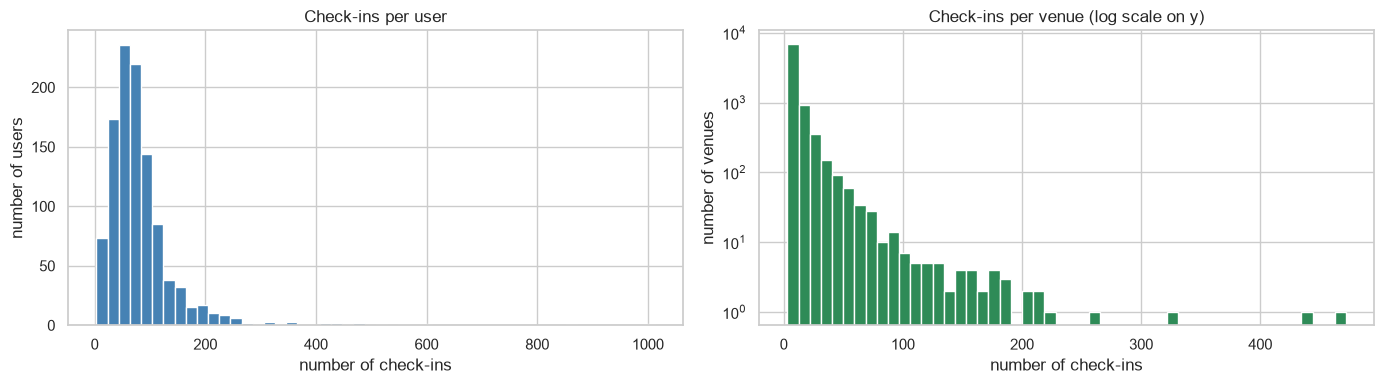

The top 10% of venues get 42% of all check-ins


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(checkins_per_user, bins=50, color="steelblue")
axes[0].set_title("Check-ins per user")
axes[0].set_xlabel("number of check-ins")
axes[0].set_ylabel("number of users")

axes[1].hist(checkins_per_venue, bins=50, color="seagreen", log=True)
axes[1].set_title("Check-ins per venue (log scale on y)")
axes[1].set_xlabel("number of check-ins")
axes[1].set_ylabel("number of venues")

plt.tight_layout()
plt.savefig(FIG + "eda02_popularity.png", dpi=150)
plt.show()

top_10_percent = checkins_per_venue.head(len(checkins_per_venue) // 10).sum() / checkins_per_venue.sum()
print(f"The top 10% of venues get {top_10_percent:.0%} of all check-ins")

**What we learned:** Most venues have only a few check-ins, but a small number have hundreds. The **top 10% of venues get 42% of
all check-ins** (a "long tail").

**How we use it:** if we only recommended the most popular places, everyone would get the same list. The backup
itinerary can pick less-crowded places from the long tail.

### EDA 3: What time of day is each theme busiest?
For each theme, the percentage of its check-ins in each hour (so small and large themes can be compared).

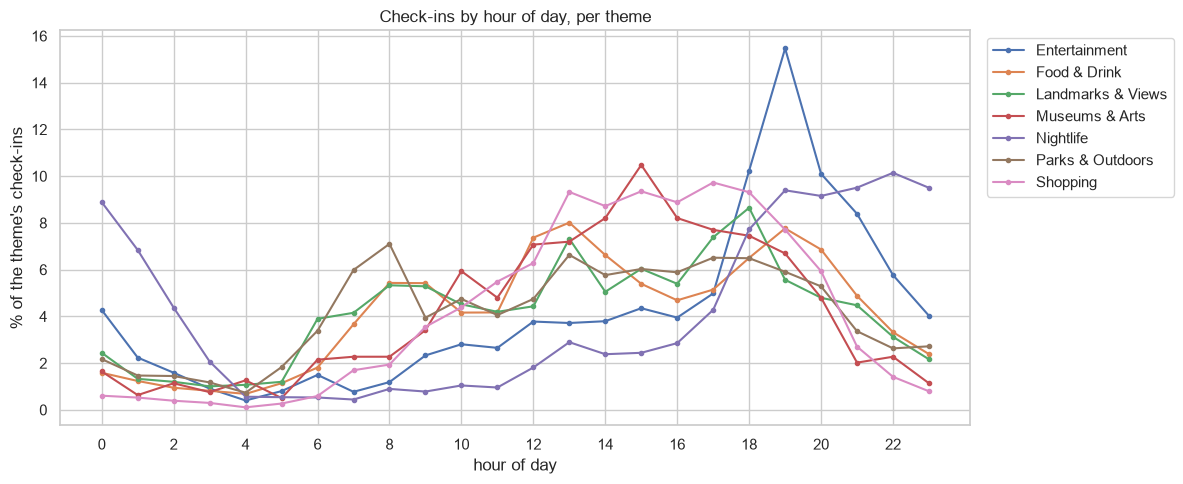

Busiest hour for each theme:
theme
Entertainment        19
Food & Drink         13
Landmarks & Views    18
Museums & Arts       15
Nightlife            22
Parks & Outdoors      8
Shopping             17
dtype: int32


In [13]:
hourly = pd.crosstab(fs["hour"], fs["theme"], normalize="columns") * 100

hourly.plot(figsize=(12, 5), marker="o", markersize=3)
plt.title("Check-ins by hour of day, per theme")
plt.xlabel("hour of day")
plt.ylabel("% of the theme's check-ins")
plt.xticks(range(0, 24, 2))
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.savefig(FIG + "eda03_hourly_by_theme.png", dpi=150)
plt.show()

print("Busiest hour for each theme:")
print(hourly.idxmax())

**What we learned:** Each theme has its own busy time: Parks peak at **8 AM** (morning runs/walks), Food at **1 PM** (lunch),
Museums at **3 PM**, Shopping at **5 PM**, Landmarks at **6 PM**, Entertainment at **7 PM** (shows) and Nightlife at **10 PM**.

**How we use it:** the itinerary schedules each stop at a sensible hour for its theme.

### EDA 4: Day of week × hour heatmap (weekday vs weekend)

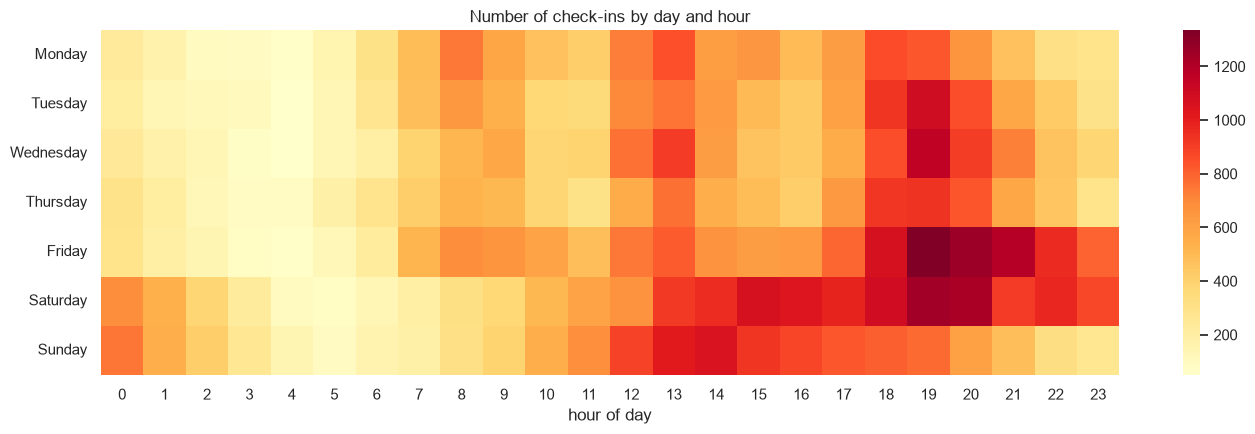

% of check-ins that happen on a weekend:
theme
Nightlife            41.2
Entertainment        36.7
Parks & Outdoors     33.9
Shopping             32.6
Museums & Arts       31.9
Food & Drink         30.2
Landmarks & Views    28.7
Name: is_weekend, dtype: float64


In [14]:
DAY_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

day_hour = pd.crosstab(fs["day_of_week"], fs["hour"]).reindex(DAY_ORDER)

plt.figure(figsize=(14, 4.5))
sns.heatmap(day_hour, cmap="YlOrRd")
plt.title("Number of check-ins by day and hour")
plt.xlabel("hour of day")
plt.ylabel("")
plt.tight_layout()
plt.savefig(FIG + "eda04_day_hour_heatmap.png", dpi=150)
plt.show()

# Weekends are 2 of 7 days (29%). A theme above 29% is more popular on weekends.
weekend_share = (fs.groupby("theme")["is_weekend"].mean() * 100).round(1).sort_values(ascending=False)
print("% of check-ins that happen on a weekend:")
print(weekend_share)

**What we learned:** Activity is highest in the afternoon and early evening, and weekend check-ins start later in the morning
and continue later at night. Weekends are 29% of the days, but **41% of Nightlife** and **37% of Entertainment**
check-ins happen on weekends, so these are more "weekend" activities.

**How we use it:** keep `is_weekend` as a feature and plan weekdays and weekends differently.

### EDA 5: The sunset effect: which themes are visited around sunset?
Share of each theme's check-ins in each light period.

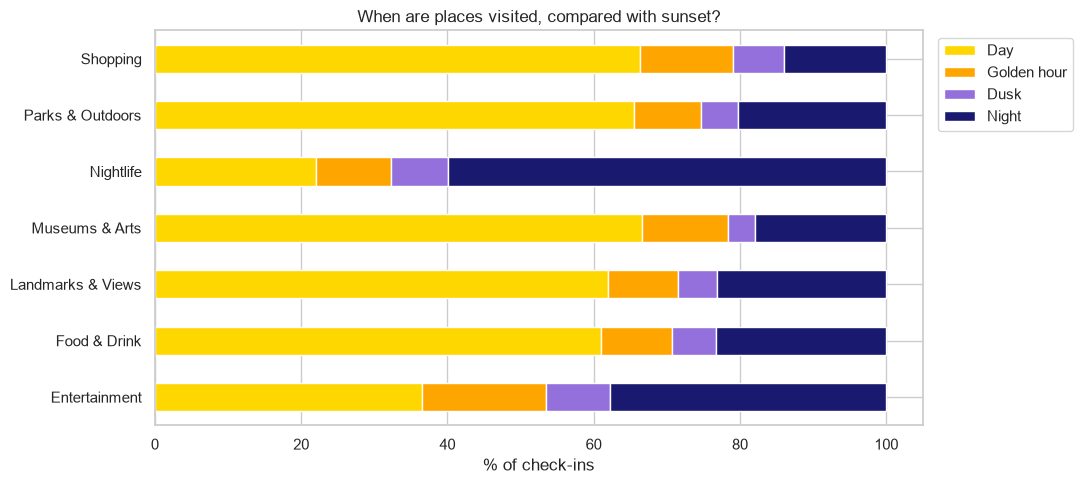

light_period,Day,Golden hour,Dusk,Night
theme,,,,
Entertainment,36.5,17.0,8.8,37.7
Food & Drink,61.0,9.8,6.0,23.3
Landmarks & Views,62.0,9.5,5.3,23.2
Museums & Arts,66.5,11.9,3.7,17.9
Nightlife,22.1,10.1,7.9,59.9
Parks & Outdoors,65.5,9.2,5.1,20.2
Shopping,66.4,12.7,7.0,14.0


In [15]:
period_order = ["Day", "Golden hour", "Dusk", "Night"]
light = pd.crosstab(fs["theme"], fs["light_period"], normalize="index")[period_order] * 100

light.plot(kind="barh", stacked=True, figsize=(11, 5), color=["gold", "orange", "mediumpurple", "midnightblue"])
plt.title("When are places visited, compared with sunset?")
plt.xlabel("% of check-ins")
plt.ylabel("")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.savefig(FIG + "eda05_sunset.png", dpi=150)
plt.show()

light.round(1)

**What we learned:** Nightlife is mostly visited at **night (60%)** as expected. **Entertainment** has the biggest golden-hour
share (17%), followed by Shopping (13%) and Museums (12%). Parks and Landmarks are mostly visited during the day.

**How we use it:** `light_period` is kept as a feature so the app can suggest "golden hour" or "after dark" stops.

### EDA 6: Where is the activity? (map of check-ins)
Each dot is a check-in, placed by its latitude and longitude.

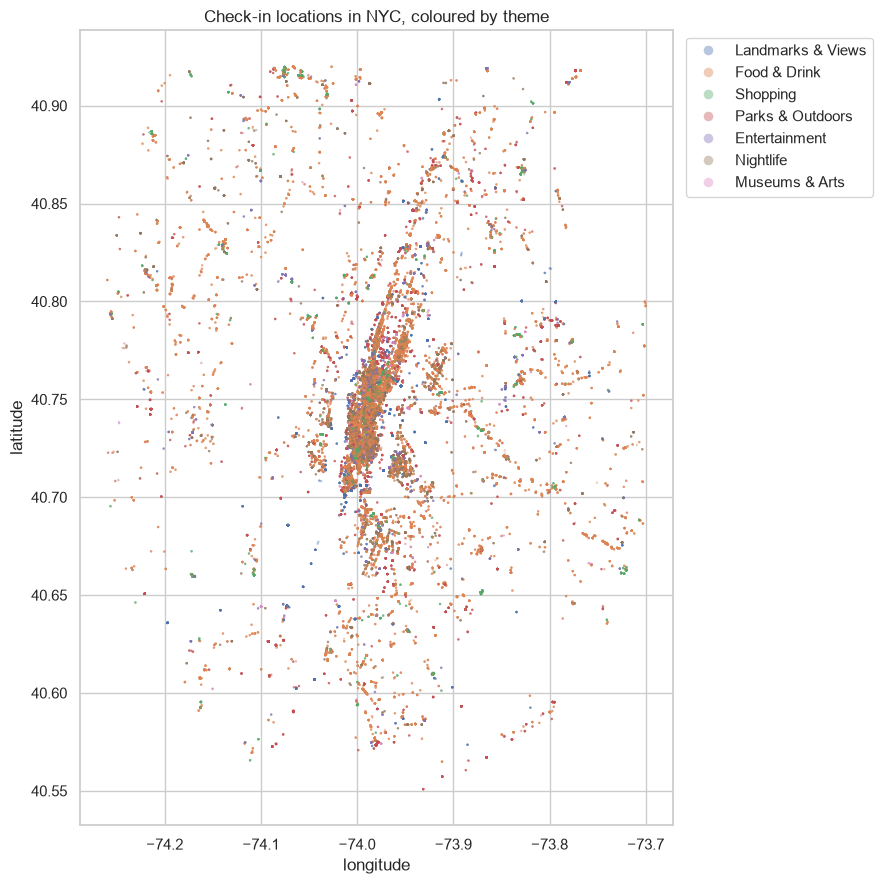

Share of check-ins in the Manhattan area: 67%


In [16]:
plt.figure(figsize=(9, 9))
sns.scatterplot(data=fs, x="longitude", y="latitude", hue="theme", s=3, alpha=0.4, linewidth=0)
plt.title("Check-in locations in NYC, coloured by theme")
plt.legend(markerscale=4, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.savefig(FIG + "eda06_map.png", dpi=150)
plt.show()

# Rough borough check: Manhattan is roughly west of -73.93 and north of 40.70
manhattan = fs["longitude"].between(-74.02, -73.93) & fs["latitude"].between(40.70, 40.88)
print(f"Share of check-ins in the Manhattan area: {manhattan.mean():.0%}")

**What we learned:** Check-ins are very concentrated in **Manhattan (about 67%)**, especially Midtown and Lower Manhattan.
Brooklyn and Queens have smaller clusters.

**How we use it:** plan each day in one area so the traveller walks between nearby stops instead of crossing the city.

### EDA 7: Brooklyn Bridge: how crowded is it at each hour?
Average pedestrians per hour, weekdays vs weekends.

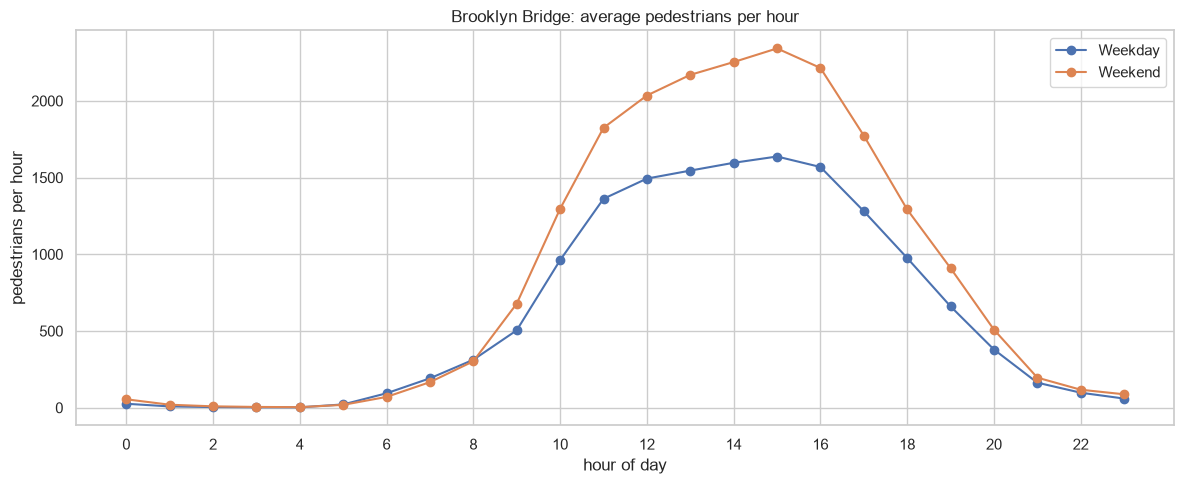

Busiest hour: {'Weekday': 15, 'Weekend': 15}
Average at 3 PM: {'Weekday': 1637.0, 'Weekend': 2342.0}
Average at 8 PM: {'Weekday': 379.0, 'Weekend': 509.0}


In [17]:
bridge_hourly = bridge.groupby(["hour", "is_weekend"])["pedestrians"].mean().unstack()
bridge_hourly.columns = ["Weekday", "Weekend"]

bridge_hourly.plot(figsize=(12, 5), marker="o")
plt.title("Brooklyn Bridge: average pedestrians per hour")
plt.xlabel("hour of day")
plt.ylabel("pedestrians per hour")
plt.xticks(range(0, 24, 2))
plt.tight_layout()
plt.savefig(FIG + "eda07_bridge_hourly.png", dpi=150)
plt.show()

print("Busiest hour:", bridge_hourly.idxmax().to_dict())
print("Average at 3 PM:", bridge_hourly.loc[15].round(0).to_dict())
print("Average at 8 PM:", bridge_hourly.loc[20].round(0).to_dict())

**What we learned:** The bridge is busiest at **3 PM** on both weekdays and weekends. Weekends are much busier
(about 2,340 vs 1,640 people per hour at 3 PM). At **8 PM** there are about **75–80% fewer people** than at 3 PM.

**How we use it:** the app can suggest visiting the bridge in the evening to avoid the crowds.

### EDA 8: Does the weather change the crowd?
Box plot of pedestrians per hour for each weather type. We use daytime hours only (10 AM – 7 PM),
otherwise night hours (always quiet) would hide the effect.

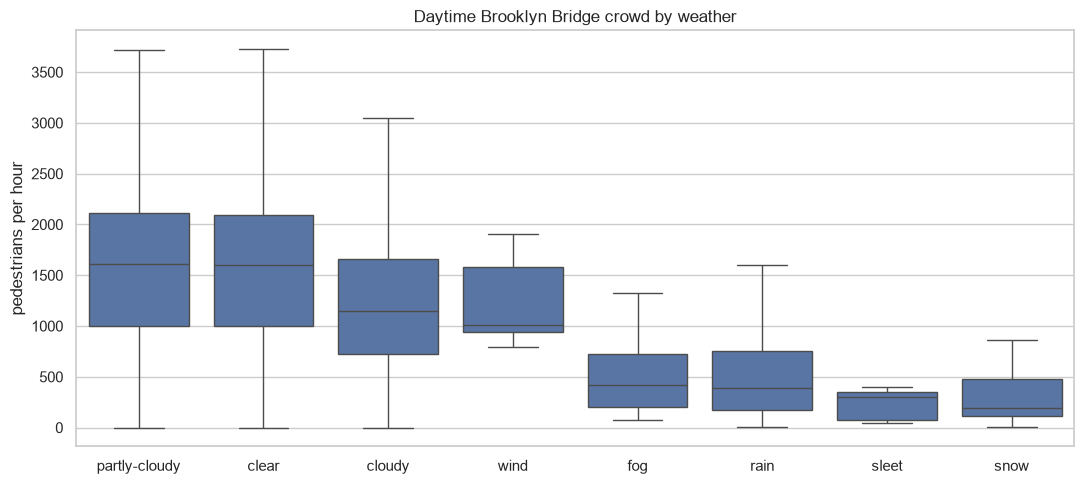

,count,mean,median
weather_summary,,,
partly-cloudy,2680,1587.0,1612.0
clear,2596,1567.0,1596.0
cloudy,940,1218.0,1146.0
wind,6,1236.0,1010.0
fog,28,499.0,416.0
rain,383,543.0,386.0
sleet,7,230.0,302.0
snow,50,335.0,191.0


In [18]:
daytime = bridge[bridge["hour"].between(10, 19)]

order = daytime.groupby("weather_summary")["pedestrians"].median().sort_values(ascending=False).index

plt.figure(figsize=(11, 5))
sns.boxplot(data=daytime, x="weather_summary", y="pedestrians", order=order, showfliers=False)
plt.title("Daytime Brooklyn Bridge crowd by weather")
plt.xlabel("")
plt.ylabel("pedestrians per hour")
plt.tight_layout()
plt.savefig(FIG + "eda08_weather.png", dpi=150)
plt.show()

daytime.groupby("weather_summary")["pedestrians"].agg(["count", "mean", "median"]).loc[order].round(0)

**What we learned:** Weather has a big effect. On clear or partly-cloudy days the median is about **1,600 people/hour**, on
rainy days about **390**, and on snowy days about **190**. (Wind, sleet and fog have very few hours, so those
boxes are less reliable.)

**How we use it:** on rainy days the app should swap outdoor stops (parks, views) for indoor ones (museums, food).

### EDA 9: Google ratings: distribution and differences between themes

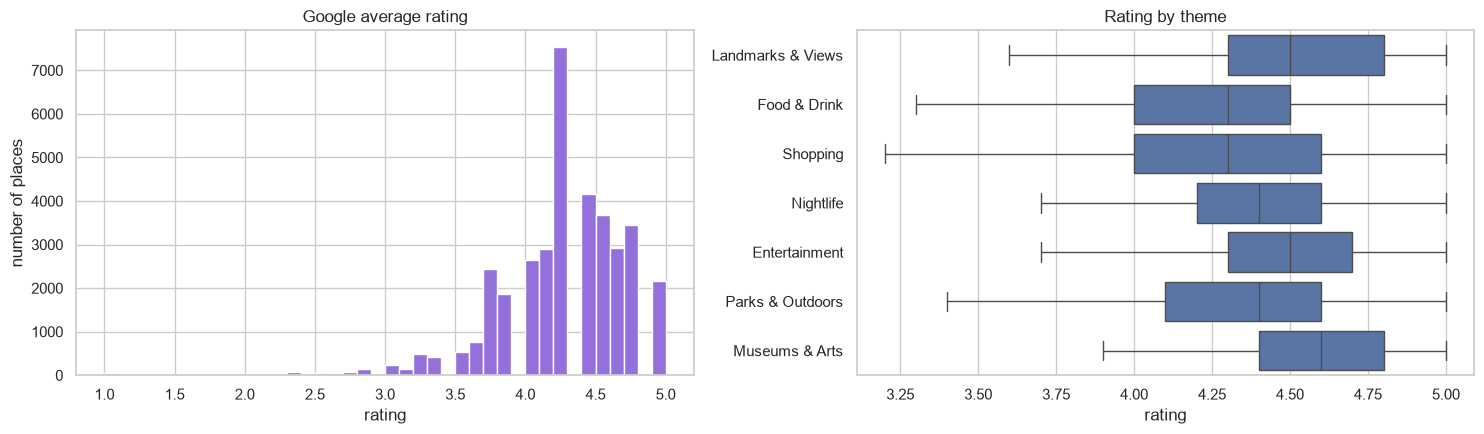

Places rated 4.0 or higher: 80%
theme
Museums & Arts       4.6
Landmarks & Views    4.5
Entertainment        4.5
Parks & Outdoors     4.4
Nightlife            4.4
Food & Drink         4.3
Shopping             4.3
Name: avg_rating, dtype: float64


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

axes[0].hist(google["avg_rating"], bins=40, color="mediumpurple")
axes[0].set_title("Google average rating")
axes[0].set_xlabel("rating")
axes[0].set_ylabel("number of places")

sns.boxplot(data=google, x="avg_rating", y="theme", ax=axes[1], showfliers=False)
axes[1].set_title("Rating by theme")
axes[1].set_xlabel("rating")
axes[1].set_ylabel("")

plt.tight_layout()
plt.savefig(FIG + "eda09_ratings.png", dpi=150)
plt.show()

print(f"Places rated 4.0 or higher: {(google['avg_rating'] >= 4).mean():.0%}")
print(google.groupby("theme")["avg_rating"].median().sort_values(ascending=False))

**What we learned:** Ratings are bunched up high: **80% of places are rated 4.0 or more**, so the rating alone does not separate
places very well. Museums & Arts have the highest median rating (4.6) and Food & Shopping the lowest (4.3).

**How we use it:** use the rating together with the number of reviews, not the rating alone.

### EDA 10: Correlation between bridge features
Which numeric features move together with the number of pedestrians?

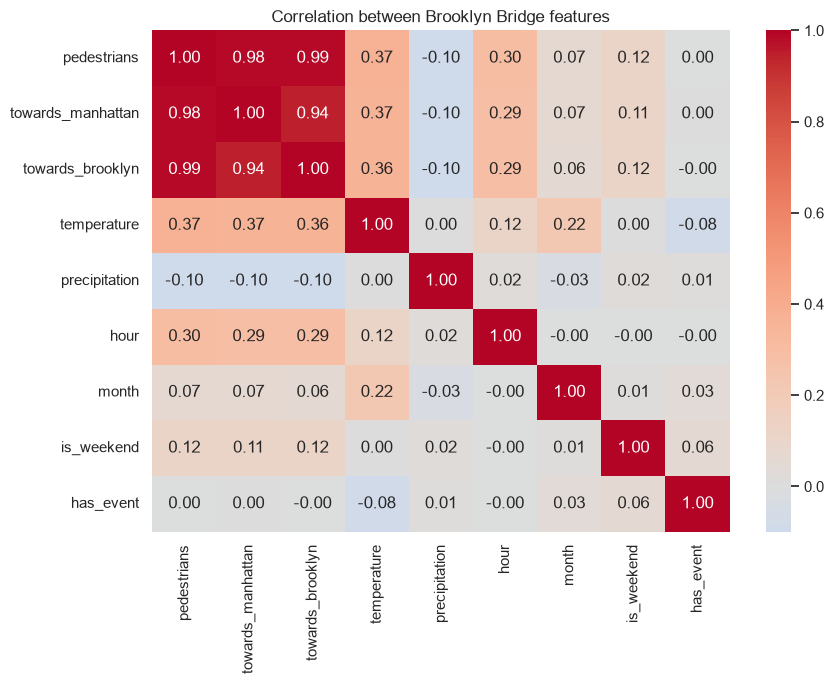

Correlation with pedestrians:
towards_brooklyn     0.99
towards_manhattan    0.98
temperature          0.37
hour                 0.30
is_weekend           0.12
month                0.07
has_event            0.00
precipitation       -0.10
Name: pedestrians, dtype: float64


In [20]:
numeric_columns = ["pedestrians", "towards_manhattan", "towards_brooklyn", "temperature", "precipitation", "hour", "month", "is_weekend", "has_event"]
corr = bridge[numeric_columns].astype(float).corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between Brooklyn Bridge features")
plt.tight_layout()
plt.savefig(FIG + "eda10_correlation.png", dpi=150)
plt.show()

print("Correlation with pedestrians:")
print(corr["pedestrians"].drop("pedestrians").sort_values(ascending=False).round(2))

**What we learned:** `towards_manhattan` and `towards_brooklyn` are almost the same as `pedestrians` (0.98–0.99) because they add up
to it, so they should **not** be used to predict crowds. **Temperature (0.37)** and **hour (0.30)** have the strongest
positive link with crowds, and precipitation has a small negative link (-0.10).

**How we use it:** to predict crowds we will use temperature, hour, weekend, month and precipitation.

Phase 2

In [60]:
# Phase 2 setup. pandas, numpy, matplotlib, seaborn and the chart style are already set by Phase 1;
# only the new Phase 2 tools are imported here.
import os
import hashlib
import warnings

from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.cluster import KMeans
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GridSearchCV, GroupKFold, TimeSeriesSplit
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, f1_score, classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, mean_absolute_error, mean_squared_error,
                             r2_score, silhouette_score, log_loss)

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42                          # same seed everywhere -> results can be repeated exactly
np.random.seed(SEED)

FIG_P2 = "../figures/phase2/"      # Phase 2 charts (Phase 1 charts stay in FIG)
RES = "../results/"                # Phase 2 tables of results
os.makedirs(FIG_P2, exist_ok=True)
os.makedirs(RES, exist_ok=True)

# One fixed colour per theme, used in every Phase 2 chart
THEME_LIST = ["Food & Drink", "Nightlife", "Parks & Outdoors", "Shopping",
              "Entertainment", "Landmarks & Views", "Museums & Arts"]
THEME_COLORS = dict(zip(THEME_LIST, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                                     "#e87ba4", "#008300", "#6250d6"]))
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
GREY = "#898781"

# The light periods created in Phase 1 (column light_period)
PERIODS = ["Day", "Golden hour", "Dusk", "Night"]


def save_fig(name):
    """Save the current chart into figures/phase2/ and show it."""
    plt.tight_layout()
    plt.savefig(FIG_P2 + name, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close("all")


SUMMARY = []   # every number the report quotes is recorded here and saved at the end


def record(algorithm, metric, value, note=""):
    """Save one result. Re-running a cell replaces its old row instead of adding a duplicate."""
    SUMMARY[:] = [s for s in SUMMARY if (s["algorithm"], s["metric"], s["note"]) != (algorithm, metric, note)]
    SUMMARY.append({"algorithm": algorithm, "metric": metric,
                    "value": round(float(value), 4), "note": note})


# Fingerprints of the files Phase 1 saved, to show at the end that Phase 2 did not change them
P1_FILES = ["foursquare_checkins_clean.csv", "google_places_clean.csv", "brooklyn_bridge_clean.csv"]


def fingerprint(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()


FINGERPRINT_BEFORE = {f: fingerprint(OUT + f) for f in P1_FILES}

In [61]:
# Phase 2 works directly on the cleaned tables Phase 1 created (fs, google, bridge).
# They are the same data Phase 1 saved in data/processed/; nothing is re-read or re-cleaned.
print("fs (Foursquare check-ins):", fs.shape, "| users:", fs["user_id"].nunique(), "| venues:", fs["venue_id"].nunique())
print("google (Google places):   ", google.shape)
print("bridge (Brooklyn Bridge): ", bridge.shape)

record("Data", "foursquare_checkins", len(fs))
record("Data", "foursquare_users", fs["user_id"].nunique())
record("Data", "foursquare_venues", fs["venue_id"].nunique())
record("Data", "google_places", len(google))
record("Data", "bridge_hours", len(bridge))

fs (Foursquare check-ins): (89118, 14) | users: 1078 | venues: 8645
google (Google places):    (36888, 9)
bridge (Brooklyn Bridge):  (16057, 15)


In [62]:
# A1 Logistic Regression: which theme suits a time slot?
# Train/test split by user: 80% of users train the model, 20% are kept for testing.
# The same split is reused later by A4 (k-NN) and A6 (Markov Chain).
rng = np.random.default_rng(SEED)
all_users = np.sort(fs["user_id"].unique())
test_users = set(rng.choice(all_users, size=int(round(0.2 * len(all_users))), replace=False))
is_test = fs["user_id"].isin(test_users).values
print(f"Train users: {len(all_users) - len(test_users)} ({(~is_test).sum()} check-ins) | "
      f"test users: {len(test_users)} ({is_test.sum()} check-ins)")

# Model inputs: Phase 1 columns hour, season, light_period (one-hot) and is_weekend
A1_FEATURES = ["hour", "season", "light_period"]


def a1_matrix(df):
    X = pd.get_dummies(df[A1_FEATURES].astype(str), dtype=float)
    X["is_weekend"] = df["is_weekend"].astype(float)
    return X


X_a1 = a1_matrix(fs)
X_a1_train, X_a1_test = X_a1[~is_test], X_a1[is_test]
y_a1_train, y_a1_test = fs["theme"].values[~is_test], fs["theme"].values[is_test]
groups_a1 = fs["user_id"].values[~is_test]
print("Features:", X_a1.shape[1], "| train rows:", len(X_a1_train), "| test rows:", len(X_a1_test))

Train users: 862 (71383 check-ins) | test users: 216 (17735 check-ins)
Features: 33 | train rows: 71383 | test rows: 17735


In [63]:
# Tuning: C x class balancing, 5-fold cross-validation grouped by user, scored with macro-F1
a1_grid = GridSearchCV(LogisticRegression(max_iter=2000),
                       {"C": [0.01, 0.1, 1, 10], "class_weight": [None, "balanced"]},
                       scoring="f1_macro", cv=GroupKFold(n_splits=5), n_jobs=-1)
a1_grid.fit(X_a1_train, y_a1_train, groups=groups_a1)

a1_cv = pd.DataFrame(a1_grid.cv_results_)[["param_C", "param_class_weight", "mean_test_score", "std_test_score"]]
a1_cv["param_class_weight"] = a1_cv["param_class_weight"].fillna("none")
print(a1_cv.sort_values("mean_test_score", ascending=False).round(4).to_string(index=False))
print("\nBest settings:", a1_grid.best_params_)
a1_model = a1_grid.best_estimator_

 param_C param_class_weight  mean_test_score  std_test_score
    0.10           balanced           0.1638          0.0098
    0.01           balanced           0.1636          0.0089
   10.00           balanced           0.1622          0.0112
    1.00           balanced           0.1622          0.0112
   10.00               none           0.1541          0.0091
    1.00               none           0.1540          0.0089
    0.10               none           0.1540          0.0090
    0.01               none           0.1515          0.0082

Best settings: {'C': 0.1, 'class_weight': 'balanced'}


In [64]:
# Evaluation on the test users
classes = a1_model.classes_
a1_proba = a1_model.predict_proba(X_a1_test)
a1_pred = classes[a1_proba.argmax(axis=1)]


def top3_accuracy(y, proba, labels):
    top3 = labels[np.argsort(-proba, axis=1)[:, :3]]
    return np.mean([y[i] in top3[i] for i in range(len(y))])


# For comparison: the best Logistic Regression WITHOUT class balancing (higher accuracy, misses rare themes)
unbalanced = a1_cv[a1_cv["param_class_weight"] == "none"].sort_values("mean_test_score", ascending=False).iloc[0]
a1_unbalanced = LogisticRegression(max_iter=2000, C=float(unbalanced["param_C"])).fit(X_a1_train, y_a1_train)

rows = []
models = {"Logistic Regression": a1_model,
          f"Logistic Regression, no balancing (C={float(unbalanced['param_C'])})": a1_unbalanced,
          "Baseline: theme frequencies (always most common)": DummyClassifier(strategy="prior"),
          "Baseline: random guess by frequency": DummyClassifier(strategy="stratified", random_state=SEED)}
for name, m in models.items():
    if name.startswith("Baseline"):
        m.fit(X_a1_train, y_a1_train)
    p = m.predict_proba(X_a1_test)
    pred = m.classes_[p.argmax(axis=1)] if name.startswith("Logistic") else m.predict(X_a1_test)
    rows.append({"model": name,
                 "accuracy": accuracy_score(y_a1_test, pred),
                 "top3_accuracy": np.nan if "random" in name else top3_accuracy(y_a1_test, p, m.classes_),
                 "macro_F1": f1_score(y_a1_test, pred, average="macro"),
                 "ROC_AUC_ovr": roc_auc_score(y_a1_test, p, multi_class="ovr", average="macro", labels=m.classes_)})
a1_results = pd.DataFrame(rows).round(4)
print(a1_results.to_string(index=False))
a1_results.to_csv(RES + "a1_results.csv", index=False)

print("\nPer-theme results (Logistic Regression):")
print(classification_report(y_a1_test, a1_pred, digits=3, zero_division=0))

for _, r in a1_results.iterrows():
    for metric in ["accuracy", "top3_accuracy", "macro_F1", "ROC_AUC_ovr"]:
        if not pd.isna(r[metric]):
            record("A1 Logistic Regression", metric, r[metric], r["model"])

                                           model  accuracy  top3_accuracy  macro_F1  ROC_AUC_ovr
                             Logistic Regression    0.1838         0.5909    0.1629       0.6372
      Logistic Regression, no balancing (C=10.0)    0.5339         0.8250    0.1517       0.6423
Baseline: theme frequencies (always most common)    0.5177         0.7789    0.0975       0.5000
             Baseline: random guess by frequency    0.3154            NaN    0.1413       0.4992

Per-theme results (Logistic Regression):
                   precision    recall  f1-score   support

    Entertainment      0.127     0.319     0.181      1249
     Food & Drink      0.650     0.038     0.072      9181
Landmarks & Views      0.072     0.082     0.077       930
   Museums & Arts      0.010     0.246     0.020       118
        Nightlife      0.379     0.512     0.436      2946
 Parks & Outdoors      0.156     0.133     0.144      1686
         Shopping      0.142     0.414     0.211      1625


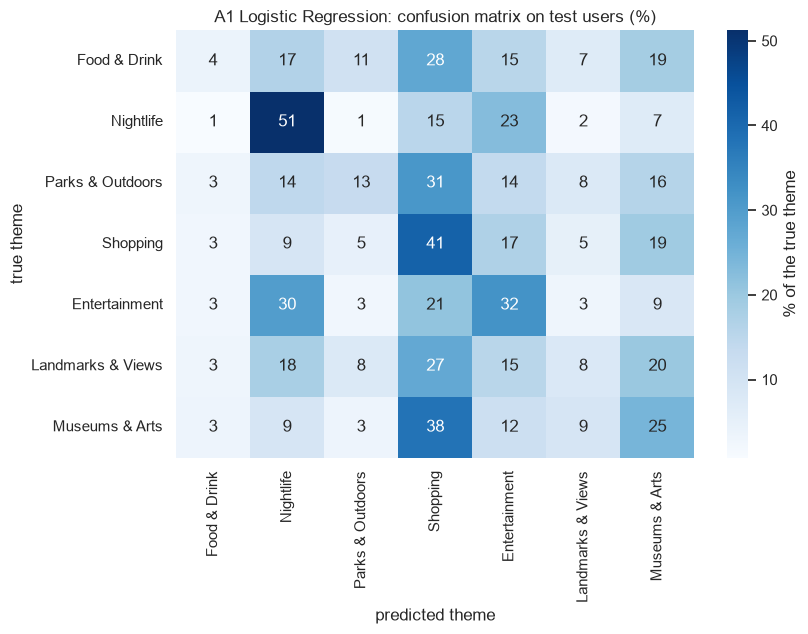

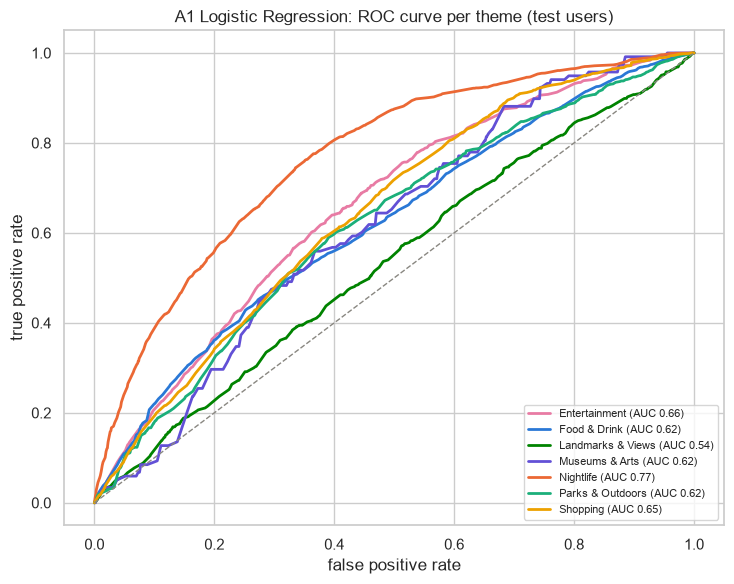

In [65]:
# Chart 1: confusion matrix (each row adds up to 100%)
theme_order = [t for t in THEME_LIST if t in classes]
cm = confusion_matrix(y_a1_test, a1_pred, labels=theme_order, normalize="true") * 100
plt.figure(figsize=(8.5, 6.5))
sns.heatmap(cm, annot=True, fmt=".0f", cmap="Blues", xticklabels=theme_order, yticklabels=theme_order,
            cbar_kws={"label": "% of the true theme"})
plt.xlabel("predicted theme")
plt.ylabel("true theme")
plt.title("A1 Logistic Regression: confusion matrix on test users (%)")
save_fig("a1_confusion.png")

# Chart 2: ROC curve for each theme (one-vs-rest)
plt.figure(figsize=(7.5, 6))
for i, theme in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_a1_test == theme, a1_proba[:, i])
    auc = roc_auc_score(y_a1_test == theme, a1_proba[:, i])
    plt.plot(fpr, tpr, color=THEME_COLORS.get(theme, GREY), lw=2, label=f"{theme} (AUC {auc:.2f})")
plt.plot([0, 1], [0, 1], ls="--", color=GREY, lw=1)
plt.xlabel("false positive rate")
plt.ylabel("true positive rate")
plt.title("A1 Logistic Regression: ROC curve per theme (test users)")
plt.legend(loc="lower right", fontsize=8)
save_fig("a1_roc.png")

Suitability by light period (1.0 = average):
              Food & Drink  Nightlife  Parks & Outdoors  Shopping  Entertainment  Landmarks & Views  Museums & Arts
light_period                                                                                                       
Day                   1.13       0.39              1.20      1.24           0.67               1.17            1.23
Golden hour           0.86       0.85              0.80      1.13           1.50               0.81            1.06
Dusk                  0.96       1.24              0.83      1.11           1.42               0.88            0.56
Night                 0.82       2.12              0.73      0.49           1.34               0.79            0.66


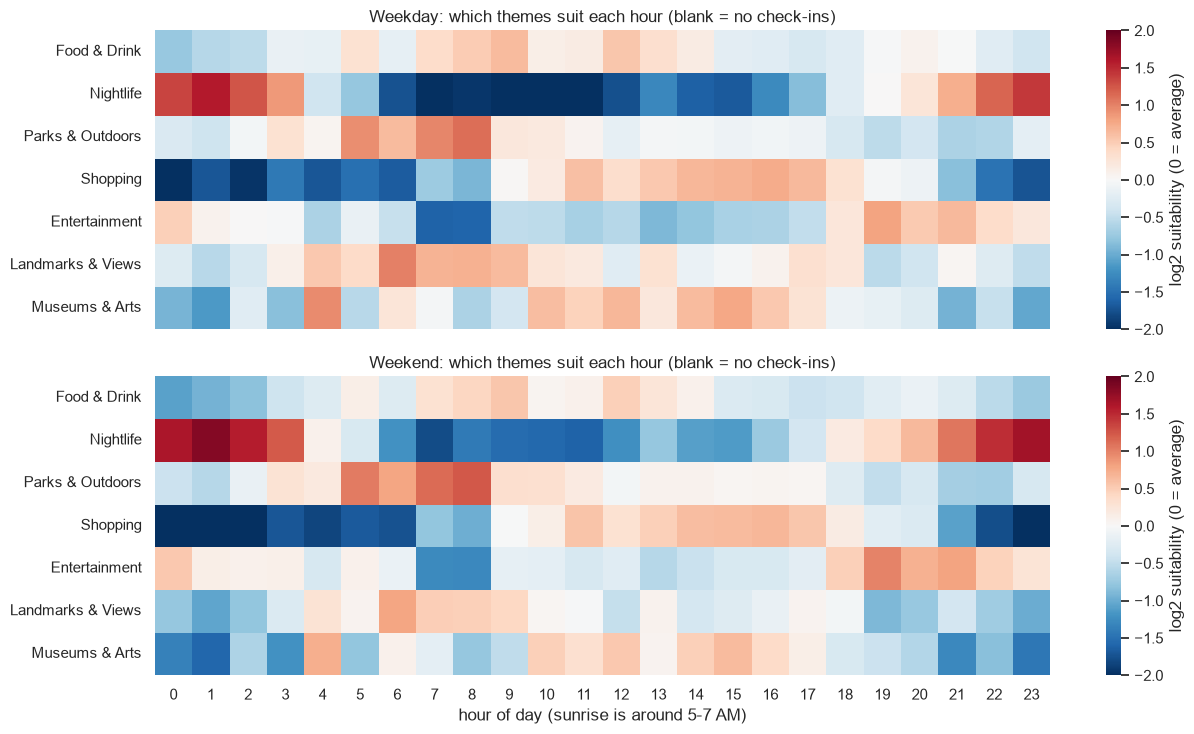


Best light period for each theme:
  Food & Drink       -> Day          (1.13x the average)
  Nightlife          -> Night        (2.12x the average)
  Parks & Outdoors   -> Day          (1.20x the average)
  Shopping           -> Day          (1.24x the average)
  Entertainment      -> Golden hour  (1.50x the average)
  Landmarks & Views  -> Day          (1.17x the average)
  Museums & Arts     -> Day          (1.23x the average)

Suitability in the early-morning hours 5-7 AM (sunrise):
Food & Drink         1.15
Nightlife            0.32
Parks & Outdoors     1.87
Shopping             0.47
Entertainment        0.57
Landmarks & Views    1.65
Museums & Arts       0.97


In [66]:
# Suitability score for the app: how much more (or less) likely a theme is in a time slot
# than on average. 1.0 = average, 2.0 = twice as likely, 0.5 = half as likely.
all_proba = pd.DataFrame(a1_model.predict_proba(X_a1), columns=classes, index=fs.index)
overall = all_proba.mean()

by_period = all_proba.groupby(fs["light_period"]).mean().reindex(PERIODS) / overall
by_period = by_period[[t for t in THEME_LIST if t in classes]]
print("Suitability by light period (1.0 = average):")
print(by_period.round(2).to_string())
by_period.round(3).to_csv(RES + "a1_suitability_by_period.csv")

fig, axes = plt.subplots(2, 1, figsize=(13, 7.5), sharex=True)
for ax, (label, flag) in zip(axes, [("Weekday", False), ("Weekend", True)]):
    mask = fs["is_weekend"].values == flag
    lift = all_proba[mask].groupby(fs.loc[mask, "hour"]).mean().reindex(range(24)) / overall
    lift = lift[[t for t in THEME_LIST if t in classes]].T
    sns.heatmap(np.log2(lift.astype(float)), ax=ax, cmap="RdBu_r", center=0, vmin=-2, vmax=2,
                cbar_kws={"label": "log2 suitability (0 = average)"})
    ax.set_title(f"{label}: which themes suit each hour (blank = no check-ins)")
    ax.set_ylabel("")
    ax.set_xlabel("")
    ax.grid(False)
axes[1].set_xlabel("hour of day (sunrise is around 5-7 AM)")
save_fig("a1_suitability.png")

print("\nBest light period for each theme:")
for theme in by_period.columns:
    best = by_period[theme].idxmax()
    print(f"  {theme:18s} -> {best:12s} ({by_period.loc[best, theme]:.2f}x the average)")
    record("A1 Logistic Regression", f"best_period_lift[{theme}]", by_period.loc[best, theme], best)

early = all_proba[fs["hour"].between(5, 7).values].mean() / overall
print("\nSuitability in the early-morning hours 5-7 AM (sunrise):")
print(early[[t for t in THEME_LIST if t in classes]].round(2).to_string())
for theme, v in early.items():
    record("A1 Logistic Regression", f"sunrise_hours_lift[{theme}]", v, "hours 5-7 AM")

In [67]:
# A2 Linear Regression: Brooklyn Bridge crowd per hour
# Train/test split by time: train on Oct 2017 - Dec 2018, test on 2019
bridge_train = bridge[bridge["hour_beginning"].dt.year <= 2018]
bridge_test = bridge[bridge["hour_beginning"].dt.year == 2019]
print("Train hours:", len(bridge_train), "| test hours:", len(bridge_test))

WEATHER = sorted(bridge["weather_summary"].dropna().unique())   # first one ("clear") is the reference


def dummies(series, categories, prefix):
    cat = series.astype(pd.CategoricalDtype(list(categories)))
    return pd.get_dummies(cat, prefix=prefix, dtype=float, drop_first=True)


def a2_matrix(df, hour_mode):
    X = pd.DataFrame(index=df.index)
    X["is_weekend"] = df["is_weekend"].astype(float)
    X["has_event"] = df["has_event"].astype(float)
    X["temperature"] = df["temperature"].astype(float)
    X["precipitation"] = df["precipitation"].astype(float)
    X = X.join(dummies(df["weather_summary"], WEATHER, "wx")).join(dummies(df["month"], range(1, 13), "month"))
    if hour_mode == "number":
        X["hour"] = df["hour"].astype(float)
    else:
        H = dummies(df["hour"], range(24), "hour")
        X = X.join(H)
        if hour_mode == "one-hot + weekend":
            X = X.join(H.mul(X["is_weekend"], axis=0).add_prefix("weekend_"))
    return X


def fit_predict_linear(X_tr, y_tr, X_te, target):
    model = LinearRegression()
    if target == "log":
        model.fit(X_tr, np.log1p(y_tr))
        pred = np.expm1(model.predict(X_te))
    else:
        model.fit(X_tr, y_tr)
        pred = model.predict(X_te)
    return model, np.clip(pred, 0, None)     # a crowd cannot be negative


def regression_scores(y, pred):
    return {"MAE": round(float(mean_absolute_error(y, pred)), 3),
            "RMSE": round(float(np.sqrt(mean_squared_error(y, pred))), 3),
            "R2": round(float(r2_score(y, pred)), 3)}

Train hours: 7296 | test hours: 8761


In [68]:
# Tuning: compare 5 versions with time-ordered cross-validation inside 2017-2018
VERSIONS = [("number", "raw"), ("one-hot", "raw"), ("one-hot", "log"),
            ("one-hot + weekend", "raw"), ("one-hot + weekend", "log")]
tscv = TimeSeriesSplit(n_splits=4)
y_tr_all = bridge_train["pedestrians"].values
rows = []
for hour_mode, target in VERSIONS:
    X_tr_all = a2_matrix(bridge_train, hour_mode).values
    maes = []
    for tr_idx, va_idx in tscv.split(X_tr_all):
        _, pred = fit_predict_linear(X_tr_all[tr_idx], y_tr_all[tr_idx], X_tr_all[va_idx], target)
        maes.append(mean_absolute_error(y_tr_all[va_idx], pred))
    rows.append({"hour as": hour_mode, "target": target, "CV_MAE": np.mean(maes), "CV_MAE_std": np.std(maes)})
a2_tuning = pd.DataFrame(rows).sort_values("CV_MAE").round(1)
print(a2_tuning.to_string(index=False))
a2_tuning.to_csv(RES + "a2_tuning.csv", index=False)

A2_HOUR, A2_TARGET = a2_tuning.iloc[0]["hour as"], a2_tuning.iloc[0]["target"]
print(f"\nChosen version: hour as '{A2_HOUR}', target '{A2_TARGET}'")

          hour as target  CV_MAE  CV_MAE_std
one-hot + weekend    raw   262.7        53.2
          one-hot    raw   274.8        58.0
          one-hot    log   354.6       231.7
one-hot + weekend    log   378.1       279.3
           number    raw   542.3       132.0

Chosen version: hour as 'one-hot + weekend', target 'raw'


In [69]:
# Final model on all of 2017-2018, tested on 2019
X_a2_train, X_a2_test = a2_matrix(bridge_train, A2_HOUR), a2_matrix(bridge_test, A2_HOUR)
y_a2_train, y_a2_test = bridge_train["pedestrians"].values, bridge_test["pedestrians"].values
a2_model, a2_pred = fit_predict_linear(X_a2_train, y_a2_train, X_a2_test, A2_TARGET)

# Baseline: average pedestrians for the same hour and weekday/weekend type in 2017-2018
hour_avg = bridge_train.groupby(["hour", "is_weekend"])["pedestrians"].mean()
baseline_pred = hour_avg.reindex(pd.MultiIndex.from_frame(bridge_test[["hour", "is_weekend"]])).values

a2_table = pd.DataFrame([{"model": "Baseline: hour average", **regression_scores(y_a2_test, baseline_pred)},
                         {"model": "Linear Regression", **regression_scores(y_a2_test, a2_pred)}]).round(3)
print(a2_table.to_string(index=False))

# Extra check: scores without the daytime hours that show 0 pedestrians (sensor gaps seen in Phase 1 EDA 8).
# These hours are only left out of this one score; the data is not changed.
keep = ~(((bridge_test["pedestrians"] == 0) & bridge_test["hour"].between(10, 19)).values)
print(f"\nWithout the {int((~keep).sum())} daytime zero hours of 2019:", regression_scores(y_a2_test[keep], a2_pred[keep]))

for _, r in a2_table.iterrows():
    for metric in ["MAE", "RMSE", "R2"]:
        record("A2 Linear Regression", metric, r[metric], r["model"])

                 model     MAE    RMSE    R2
Baseline: hour average 328.876 514.462 0.672
     Linear Regression 291.984 444.782 0.755

Without the 25 daytime zero hours of 2019: {'MAE': 289.026, 'RMSE': 438.692, 'R2': 0.762}


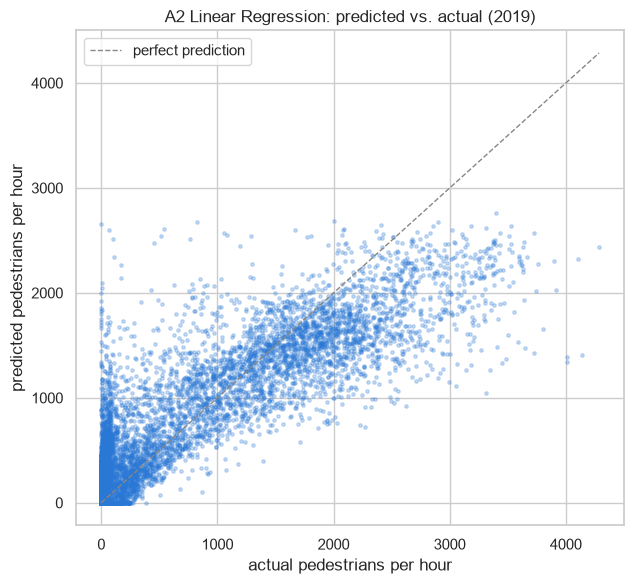

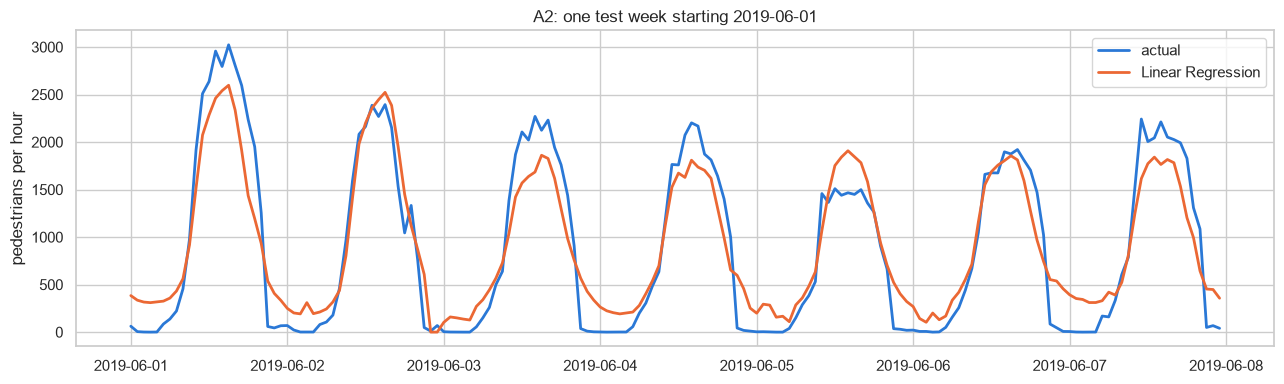

In [70]:
# Chart 1: predicted vs. actual (2019)
plt.figure(figsize=(6.5, 6))
plt.scatter(y_a2_test, a2_pred, s=6, alpha=0.25, color=SERIES[0])
lim = max(y_a2_test.max(), a2_pred.max())
plt.plot([0, lim], [0, lim], ls="--", color=GREY, lw=1, label="perfect prediction")
plt.xlabel("actual pedestrians per hour")
plt.ylabel("predicted pedestrians per hour")
plt.title("A2 Linear Regression: predicted vs. actual (2019)")
plt.legend()
save_fig("a2_pred_vs_actual.png")

# Chart 2: one test week, actual vs. predicted
week_start = bridge_test.loc[bridge_test["hour_beginning"].dt.month == 6, "hour_beginning"].dt.normalize().min()
week = (bridge_test["hour_beginning"] >= week_start) & (bridge_test["hour_beginning"] < week_start + pd.Timedelta(days=7))
plt.figure(figsize=(13, 4))
plt.plot(bridge_test.loc[week, "hour_beginning"], y_a2_test[week.values], color=SERIES[0], lw=2, label="actual")
plt.plot(bridge_test.loc[week, "hour_beginning"], a2_pred[week.values], color=SERIES[1], lw=2, label="Linear Regression")
plt.ylabel("pedestrians per hour")
plt.title(f"A2: one test week starting {week_start.date()}")
plt.legend()
save_fig("a2_week.png")

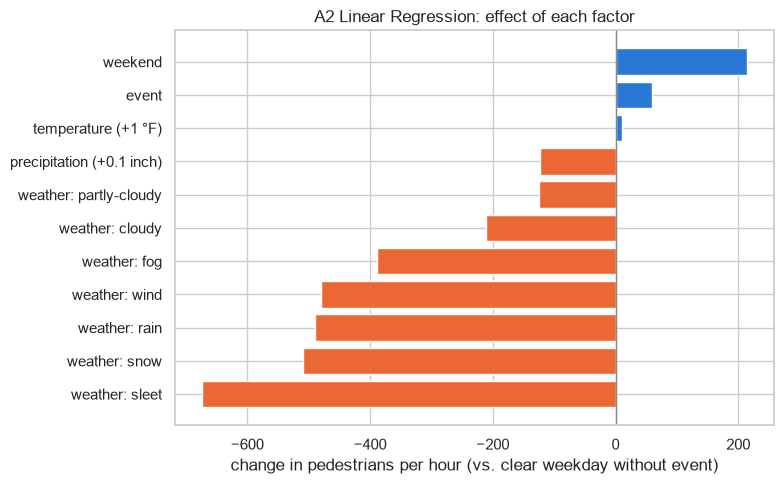

weather: sleet              -673.33
weather: snow               -509.94
weather: rain               -490.26
weather: wind               -479.81
weather: fog                -388.57
weather: cloudy             -210.77
weather: partly-cloudy      -124.28
precipitation (+0.1 inch)   -123.91
temperature (+1 °F)            9.94
event                         59.24
weekend                      213.86


In [71]:
# Chart 3: what each factor does (coefficients, excluding hour and month columns)
coef = pd.Series(a2_model.coef_, index=X_a2_train.columns)
effects = coef[[c for c in coef.index if not c.startswith(("hour_", "month_", "weekend_hour"))]].copy()
effects.index = [c.replace("wx_", "weather: ") for c in effects.index]
effects = effects.rename(index={"precipitation": "precipitation (+0.1 inch)",
                                "temperature": "temperature (+1 °F)",
                                "is_weekend": "weekend", "has_event": "event"})
effects.loc["precipitation (+0.1 inch)"] *= 0.1
if A2_TARGET == "log":
    effects = (np.exp(effects) - 1) * 100
    xlabel = "% change in pedestrians (vs. clear weekday without event)"
else:
    xlabel = "change in pedestrians per hour (vs. clear weekday without event)"


# With per-hour weekend columns, the weekend effect is spread over many coefficients, so it is
# measured from predictions instead: the same 2019 hours predicted as weekdays and as weekends.
def predict_linear(model, X):
    pred = model.predict(X)
    return np.clip(np.expm1(pred) if A2_TARGET == "log" else pred, 0, None)


p_weekday = predict_linear(a2_model, a2_matrix(bridge_test.assign(is_weekend=False), A2_HOUR))
p_weekend = predict_linear(a2_model, a2_matrix(bridge_test.assign(is_weekend=True), A2_HOUR))
effects.loc["weekend"] = ((p_weekend.mean() / p_weekday.mean() - 1) * 100 if A2_TARGET == "log"
                          else (p_weekend - p_weekday).mean())
effects = effects.sort_values()

plt.figure(figsize=(8, 5))
plt.barh(effects.index, effects.values, color=[SERIES[1] if v < 0 else SERIES[0] for v in effects.values])
plt.axvline(0, color=GREY, lw=1)
plt.xlabel(xlabel)
plt.title("A2 Linear Regression: effect of each factor")
save_fig("a2_effects.png")
print(effects.round(2).to_string())
for name, v in effects.items():
    record("A2 Linear Regression", f"effect[{name}]", v, "% change" if A2_TARGET == "log" else "people/hour")

In [72]:
# A5 Random Forest (outside class): same task and split as A2
# Reference: L. Breiman, "Random Forests," Machine Learning, vol. 45, pp. 5-32, 2001.
WEATHER_CODE = {w: i for i, w in enumerate(WEATHER)}
A5_FEATURES = ["hour", "month", "is_weekend", "has_event", "temperature", "precipitation", "weather_code"]


def a5_matrix(df):
    X = pd.DataFrame(index=df.index)
    for col in ["hour", "month", "is_weekend", "has_event", "temperature", "precipitation"]:
        X[col] = df[col].astype(float)
    X["weather_code"] = df["weather_summary"].map(WEATHER_CODE).astype(float)
    return X[A5_FEATURES]


X_a5_train, X_a5_test = a5_matrix(bridge_train), a5_matrix(bridge_test)

a5_grid = GridSearchCV(RandomForestRegressor(random_state=SEED, n_jobs=-1),
                       {"n_estimators": [100, 300], "max_depth": [None, 10, 20], "min_samples_leaf": [1, 5]},
                       scoring="neg_mean_absolute_error", cv=TimeSeriesSplit(n_splits=4))
a5_grid.fit(X_a5_train, y_a2_train)

a5_cv = pd.DataFrame(a5_grid.cv_results_)[["param_n_estimators", "param_max_depth", "param_min_samples_leaf", "mean_test_score"]]
a5_cv["CV_MAE"] = -a5_cv.pop("mean_test_score")
a5_cv["param_max_depth"] = a5_cv["param_max_depth"].fillna("none")
print(a5_cv.sort_values("CV_MAE").round(1).to_string(index=False))
print("\nBest settings:", a5_grid.best_params_)
a5_model = a5_grid.best_estimator_
a5_pred = a5_model.predict(X_a5_test)

 param_n_estimators param_max_depth  param_min_samples_leaf  CV_MAE
                100              20                       5   211.9
                100            none                       5   211.9
                100              10                       5   212.2
                300              10                       1   212.3
                300              20                       5   212.4
                300            none                       5   212.5
                300              10                       5   212.9
                100              10                       1   213.1
                300              20                       1   213.3
                300            none                       1   213.5
                100            none                       1   214.4
                100              20                       1   214.6

Best settings: {'max_depth': 20, 'min_samples_leaf': 5, 'n_estimators': 100}


                 model     MAE    RMSE    R2
Baseline: hour average 328.876 514.462 0.672
  A2 Linear Regression 291.984 444.782 0.755
      A5 Random Forest 211.751 355.819 0.843

Random Forest without daytime zero hours: {'MAE': 209.846, 'RMSE': 352.517, 'R2': 0.846}


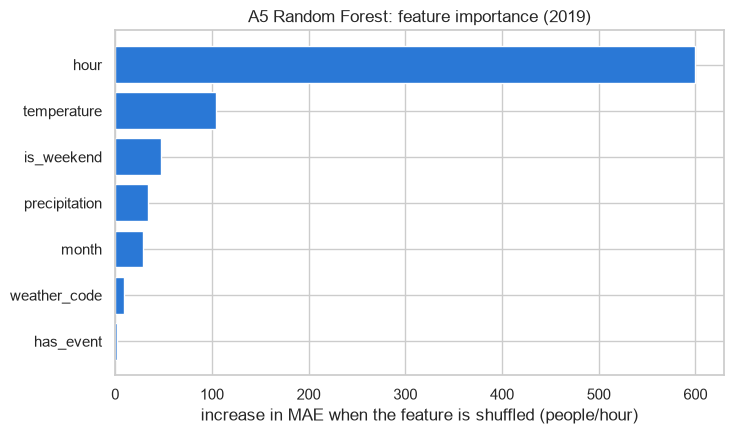

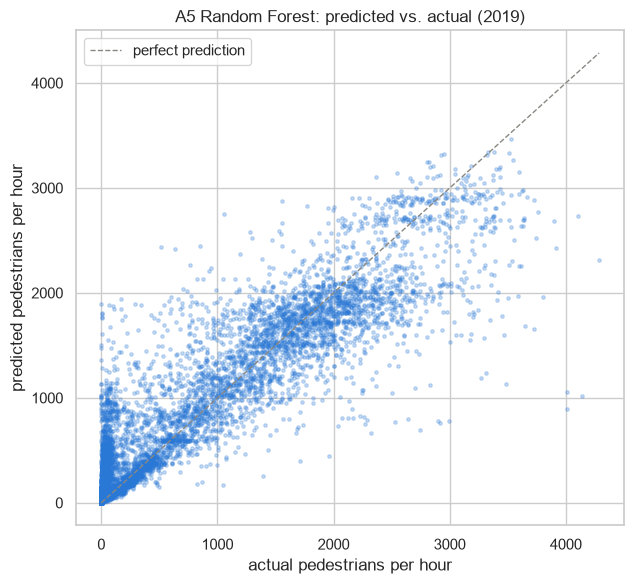

In [73]:
# Comparison on 2019: baseline vs. Linear Regression vs. Random Forest
comparison = pd.DataFrame([{"model": "Baseline: hour average", **regression_scores(y_a2_test, baseline_pred)},
                           {"model": "A2 Linear Regression", **regression_scores(y_a2_test, a2_pred)},
                           {"model": "A5 Random Forest", **regression_scores(y_a2_test, a5_pred)}]).round(3)
print(comparison.to_string(index=False))
comparison.to_csv(RES + "a2_a5_comparison.csv", index=False)
print("\nRandom Forest without daytime zero hours:", regression_scores(y_a2_test[keep], a5_pred[keep]))
r = comparison.set_index("model").loc["A5 Random Forest"]
for metric in ["MAE", "RMSE", "R2"]:
    record("A5 Random Forest", metric, r[metric], "A5 Random Forest")

# Chart 1: which features matter (permutation importance on 2019)
imp = permutation_importance(a5_model, X_a5_test, y_a2_test, scoring="neg_mean_absolute_error",
                             n_repeats=5, random_state=SEED, n_jobs=-1)
importance = pd.Series(imp.importances_mean, index=A5_FEATURES).sort_values()
plt.figure(figsize=(7.5, 4.5))
plt.barh(importance.index, importance.values, color=SERIES[0])
plt.xlabel("increase in MAE when the feature is shuffled (people/hour)")
plt.title("A5 Random Forest: feature importance (2019)")
save_fig("a5_importance.png")
for name, v in importance.items():
    record("A5 Random Forest", f"importance[{name}]", v, "MAE increase")

# Chart 2: predicted vs. actual
plt.figure(figsize=(6.5, 6))
plt.scatter(y_a2_test, a5_pred, s=6, alpha=0.25, color=SERIES[0])
lim = max(y_a2_test.max(), a5_pred.max())
plt.plot([0, lim], [0, lim], ls="--", color=GREY, lw=1, label="perfect prediction")
plt.xlabel("actual pedestrians per hour")
plt.ylabel("predicted pedestrians per hour")
plt.title("A5 Random Forest: predicted vs. actual (2019)")
plt.legend()
save_fig("a5_pred_vs_actual.png")

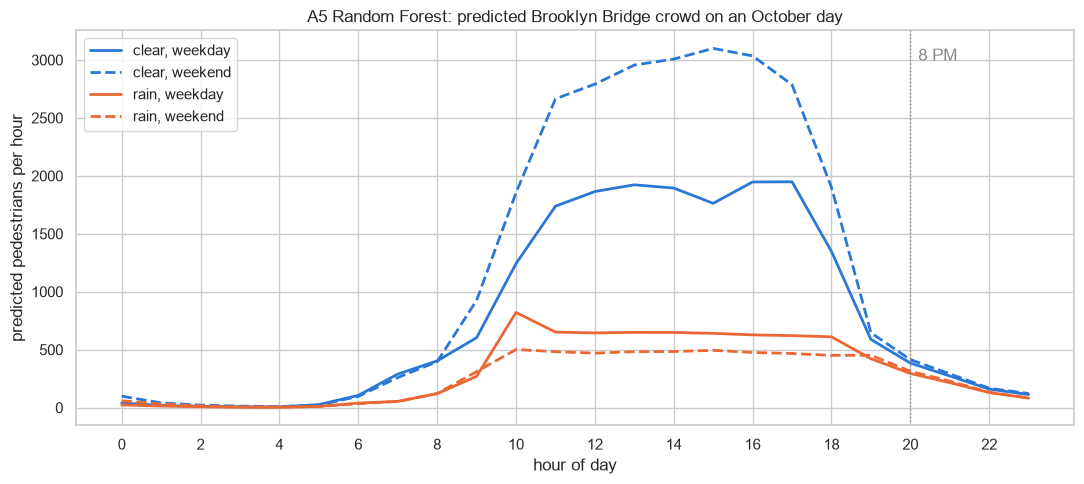

Predicted crowd at 3 PM vs 8 PM (October):
  clear, weekday    3 PM:   1763 | 8 PM:    384 |   78% fewer at 8 PM
  clear, weekend    3 PM:   3100 | 8 PM:    414 |   87% fewer at 8 PM
  rain, weekday     3 PM:    640 | 8 PM:    294 |   54% fewer at 8 PM
  rain, weekend     3 PM:    494 | 8 PM:    313 |   37% fewer at 8 PM


In [74]:
# Chart 3: the "best time to walk the bridge" chart for the app
# Scenario: a day in October, typical October temperature for each hour, no event.
october = bridge[bridge["month"] == 10]
temp_by_hour = october.groupby("hour")["temperature"].median().reindex(range(24)).interpolate().bfill().ffill()
rain_precip = bridge.loc[(bridge["weather_summary"] == "rain") & (bridge["precipitation"] > 0), "precipitation"].median()
rain_precip = 0.0 if np.isnan(rain_precip) else rain_precip

scenarios = {}
for weather in ["clear", "rain"]:
    if weather not in WEATHER_CODE:
        continue
    for weekend in [False, True]:
        grid = pd.DataFrame({"hour": range(24), "month": 10, "is_weekend": float(weekend), "has_event": 0.0,
                             "temperature": temp_by_hour.values,
                             "precipitation": rain_precip if weather == "rain" else 0.0,
                             "weather_code": WEATHER_CODE[weather]})[A5_FEATURES].astype(float)
        scenarios[(weather, weekend)] = a5_model.predict(grid)

plt.figure(figsize=(11, 5))
for (weather, weekend), pred in scenarios.items():
    plt.plot(range(24), pred, lw=2, ls="--" if weekend else "-",
             color=SERIES[0] if weather == "clear" else SERIES[1],
             label=f"{weather}, {'weekend' if weekend else 'weekday'}")
plt.axvline(20, color=GREY, lw=1, ls=":")
plt.text(20.2, plt.ylim()[1] * 0.92, "8 PM", color=GREY)
plt.xticks(range(0, 24, 2))
plt.xlabel("hour of day")
plt.ylabel("predicted pedestrians per hour")
plt.title("A5 Random Forest: predicted Brooklyn Bridge crowd on an October day")
plt.legend()
save_fig("a5_best_time.png")

print("Predicted crowd at 3 PM vs 8 PM (October):")
for (weather, weekend), pred in scenarios.items():
    label = f"{weather}, {'weekend' if weekend else 'weekday'}"
    drop = (1 - pred[20] / pred[15]) * 100 if pred[15] > 0 else np.nan
    print(f"  {label:17s} 3 PM: {pred[15]:6.0f} | 8 PM: {pred[20]:6.0f} | {drop:4.0f}% fewer at 8 PM")
    record("A5 Random Forest", f"october_3pm[{label}]", pred[15], "predicted people/hour")
    record("A5 Random Forest", f"october_8pm[{label}]", pred[20], "predicted people/hour")

Venues: 8645
 k   inertia  silhouette
 2 39436.524       0.242
 3 33215.342       0.256
 4 28193.150       0.276
 5 24262.665       0.265
 6 21419.796       0.260
 7 20028.138       0.243
 8 18924.175       0.238

Chosen k: 4


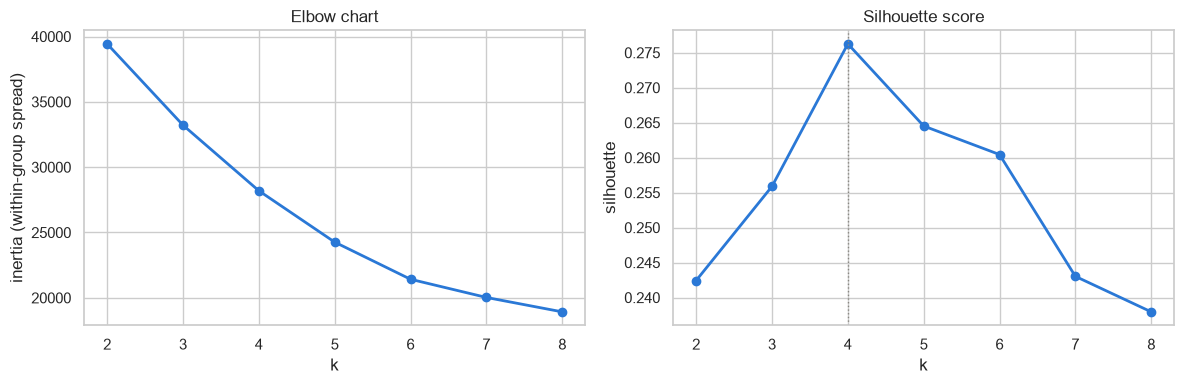

In [75]:
# A3 k-Means: group places by when they are visited
# Model input: one row per venue, summarising its Phase 1 check-ins
# (share of visits in each light_period, share on weekends, log of the number of check-ins).
def build_venue_table(df):
    shares = (pd.crosstab(df["venue_id"], df["light_period"], normalize="index")
              .reindex(columns=PERIODS, fill_value=0))
    info = df.groupby("venue_id").agg(checkins=("user_id", "size"),
                                      weekend_share=("is_weekend", "mean"),
                                      latitude=("latitude", "mean"),
                                      longitude=("longitude", "mean"),
                                      theme=("theme", lambda s: s.mode().iloc[0]))
    table = info.join(shares)
    table["log_checkins"] = np.log1p(table["checkins"])
    return table


venues_all = build_venue_table(fs)
print("Venues:", len(venues_all))

A3_FEATURES = PERIODS + ["weekend_share", "log_checkins"]
X_a3 = StandardScaler().fit_transform(venues_all[A3_FEATURES])

rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_a3)
    sil = silhouette_score(X_a3, km.labels_, sample_size=min(5000, len(X_a3)), random_state=SEED)
    rows.append({"k": k, "inertia": km.inertia_, "silhouette": sil})
a3_tuning = pd.DataFrame(rows)
print(a3_tuning.round(3).to_string(index=False))
a3_tuning.to_csv(RES + "a3_tuning.csv", index=False)

A3_K = int(a3_tuning[a3_tuning["k"] >= 3].sort_values("silhouette", ascending=False).iloc[0]["k"])
print("\nChosen k:", A3_K)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(a3_tuning["k"], a3_tuning["inertia"], marker="o", color=SERIES[0], lw=2)
axes[0].set_title("Elbow chart")
axes[0].set_xlabel("k")
axes[0].set_ylabel("inertia (within-group spread)")
axes[1].plot(a3_tuning["k"], a3_tuning["silhouette"], marker="o", color=SERIES[0], lw=2)
axes[1].axvline(A3_K, color=GREY, ls=":", lw=1)
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("k")
axes[1].set_ylabel("silhouette")
save_fig("a3_elbow_silhouette.png")

                         Day  Golden hour  Dusk  Night  weekend_share  median check-ins  venues
group                                                                                          
G0: Golden hour places  36.6         38.0   3.7   21.7           37.5               4.0    1502
G1: Day places          83.8          4.6   2.0    9.6           30.1               6.0    3660
G2: Dusk places         33.4         10.2  31.1   25.3           36.4               4.0    1231
G3: Night places        20.0          5.7   4.6   69.8           40.1               7.0    2252


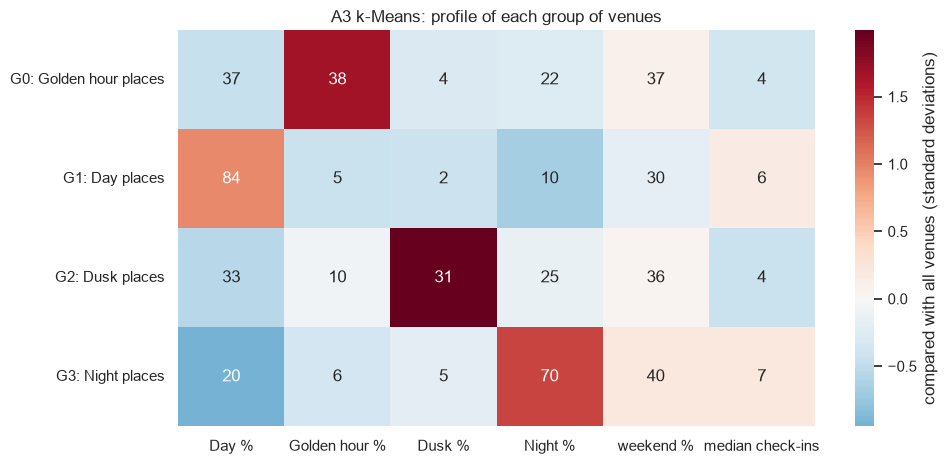

In [77]:
a3_model = KMeans(n_clusters=A3_K, n_init=10, random_state=SEED).fit(X_a3)
a3_labels = pd.Series(a3_model.labels_, index=venues_all.index)
a3_sil = silhouette_score(X_a3, a3_model.labels_, sample_size=min(5000, len(X_a3)), random_state=SEED)
record("A3 k-Means", "k", A3_K)
record("A3 k-Means", "silhouette", a3_sil)

# Name each group by the light period it leans to most (compared with all venues)
z_means = pd.DataFrame(X_a3, columns=A3_FEATURES).groupby(a3_model.labels_).mean()
names = {}
for c, row in z_means.iterrows():
    name = f"{row[PERIODS].idxmax()} places"
    if row["weekend_share"] > 0.5:
        name += ", weekend"
    if row["log_checkins"] > 0.5:
        name += ", popular"
    names[c] = f"G{c}: {name}"
group_name = a3_labels.map(names).rename("group")

profile = venues_all[PERIODS + ["weekend_share"]].groupby(group_name).mean() * 100
profile["median check-ins"] = venues_all["checkins"].groupby(group_name).median()
profile["venues"] = group_name.value_counts()
print(profile.round(1).to_string())
for name, size in profile["venues"].items():
    record("A3 k-Means", f"size[{name}]", size)

# Chart: group profiles. Colour = above/below the average venue; numbers = real values
z_plot = z_means.rename(index=names)[A3_FEATURES]
annot = profile[PERIODS + ["weekend_share"]].round(0).astype(int).astype(str)
annot["log_checkins"] = profile["median check-ins"].round(0).astype(int).astype(str)
plt.figure(figsize=(10, 0.7 * A3_K + 2))
sns.heatmap(z_plot, annot=annot.loc[z_plot.index].values, fmt="", cmap="RdBu_r", center=0,
            cbar_kws={"label": "compared with all venues (standard deviations)"},
            xticklabels=[p + " %" for p in PERIODS] + ["weekend %", "median check-ins"])
plt.ylabel("")
plt.title("A3 k-Means: profile of each group of venues")
save_fig("a3_profiles.png")

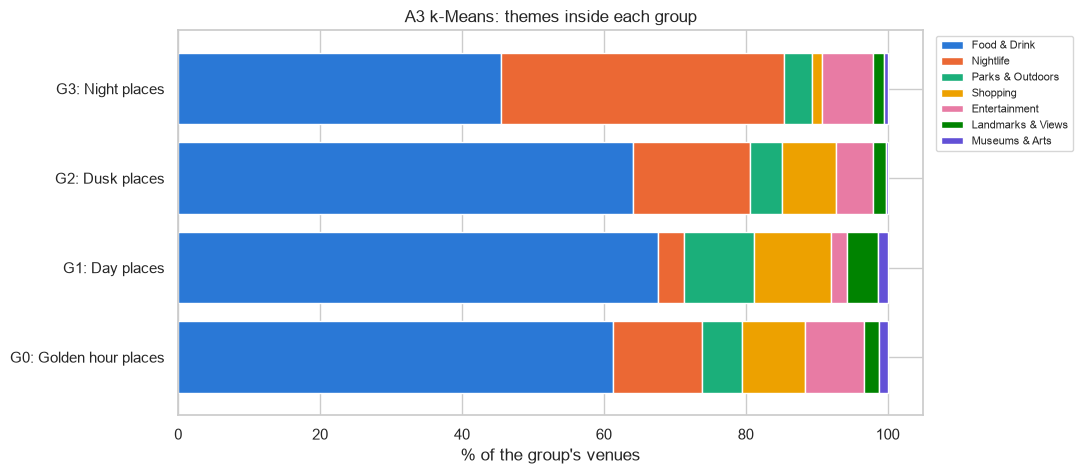

theme                   Food & Drink  Nightlife  Parks & Outdoors  Shopping  Entertainment  Landmarks & Views  Museums & Arts
group                                                                                                                        
G0: Golden hour places          61.3       12.6               5.6       9.0            8.2                2.1             1.3
G1: Day places                  67.6        3.7               9.9      10.8            2.2                4.4             1.4
G2: Dusk places                 64.1       16.5               4.5       7.7            5.1                1.9             0.2
G3: Night places                45.5       39.9               3.9       1.5            7.1                1.5             0.5


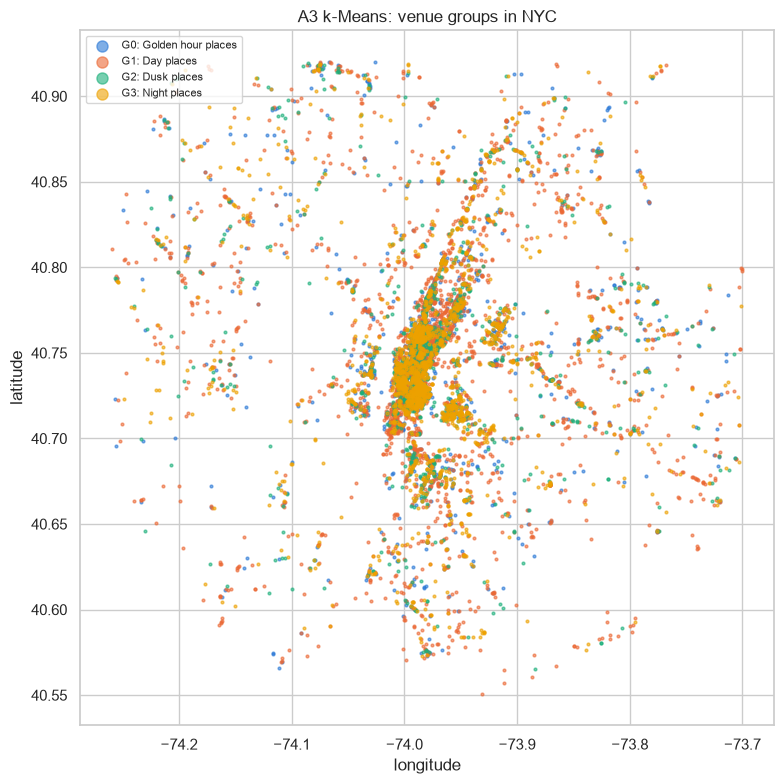

In [78]:
# Chart: theme mix in each group
mix = pd.crosstab(group_name, venues_all["theme"], normalize="index").reindex(columns=THEME_LIST, fill_value=0) * 100
ax = mix.plot(kind="barh", stacked=True, figsize=(11, 0.6 * A3_K + 2.5), width=0.8,
              color=[THEME_COLORS[t] for t in THEME_LIST], edgecolor="white", linewidth=1)
ax.set_xlabel("% of the group's venues")
ax.set_ylabel("")
ax.set_title("A3 k-Means: themes inside each group")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
save_fig("a3_theme_mix.png")
print(mix.round(1).to_string())

# Chart: where the groups are on the map
plt.figure(figsize=(8, 8))
for c in sorted(names):
    sub = venues_all[a3_labels == c]
    plt.scatter(sub["longitude"], sub["latitude"], s=4, alpha=0.6, color=SERIES[c % len(SERIES)], label=names[c])
plt.xlabel("longitude")
plt.ylabel("latitude")
plt.title("A3 k-Means: venue groups in NYC")
plt.legend(markerscale=4, fontsize=8, loc="upper left")
save_fig("a3_map.png")

pd.DataFrame({"theme": venues_all["theme"], "checkins": venues_all["checkins"],
              "group": group_name}).to_csv(RES + "a3_venue_groups.csv")

In [79]:
# A4 k-NN: personalized place suggestions (item-based k-NN)
# Model input: the same per-venue summary as A3, built from TRAIN users only (no information leak).
venues_train = build_venue_table(fs[~is_test])
cand_ids = venues_train.index.to_numpy()
id_pos = {v: i for i, v in enumerate(cand_ids)}
popular_order = venues_train["checkins"].sort_values(ascending=False).index.to_numpy()
user_groups = {u: g.sort_values("local_time") for u, g in fs.groupby("user_id")}
KS = [5, 10, 20]
N_NEIGHBORS = 20


def a4_features(table, location_weight, popularity_weight):
    theme = pd.get_dummies(table["theme"].astype(pd.CategoricalDtype(THEME_LIST)), dtype=float).values
    shares = table[PERIODS].values
    loc = table[["latitude", "longitude"]]
    loc = ((loc - loc.mean()) / loc.std()).values
    pop = ((table["log_checkins"] - table["log_checkins"].mean()) / table["log_checkins"].std()).values[:, None]
    return np.hstack([theme, shares, location_weight * loc, popularity_weight * pop])


def recommend(hist_known, seen, F, nn):
    """Item-based k-NN: each history venue votes for its nearest venues."""
    visits = pd.Series(hist_known).value_counts()
    dist, idx = nn.kneighbors(F[[id_pos[v] for v in visits.index]], n_neighbors=min(len(cand_ids), N_NEIGHBORS + 1))
    votes = {}
    for n_visits, d_row, i_row in zip(visits.values, dist, idx):
        for d, i in zip(d_row, i_row):
            v = cand_ids[i]
            if v not in seen:
                votes[v] = votes.get(v, 0.0) + n_visits / (1.0 + d)
    return sorted(votes, key=votes.get, reverse=True)


def split_user(uid):
    """First 80% of a user's check-ins (by time) = history; new venues in the last 20% = answers."""
    u = user_groups[uid]
    cut = int(np.ceil(0.8 * len(u)))
    hist, future = u.iloc[:cut], u.iloc[cut:]
    seen = set(hist["venue_id"])
    hist_known = [v for v in hist["venue_id"] if v in id_pos]
    target = (set(future["venue_id"]) - seen) & set(id_pos)
    return hist_known, seen, target


def evaluate_users(user_ids, F, nn, seed=SEED):
    rand = np.random.default_rng(seed)
    out = {m: {K: [] for K in KS} for m in ["k-NN", "Most popular", "Random"]}
    for uid in user_ids:
        hist_known, seen, target = split_user(uid)
        if not hist_known or not target:
            continue
        need = max(KS) + len(seen)
        lists = {"k-NN": recommend(hist_known, seen, F, nn),
                 "Most popular": [v for v in popular_order[:need] if v not in seen],
                 "Random": [v for v in rand.choice(cand_ids, size=min(len(cand_ids), need), replace=False) if v not in seen]}
        for m, lst in lists.items():
            for K in KS:
                hits = len(set(lst[:K]) & target)
                out[m][K].append((hits / K, hits / len(target), hits > 0))
    rows = []
    for m in out:
        for K in KS:
            arr = np.array(out[m][K], dtype=float)
            rows.append({"method": m, "K": K, "users_scored": len(arr), "Precision@K": arr[:, 0].mean(),
                         "Recall@K": arr[:, 1].mean(), "HitRate@K": arr[:, 2].mean()})
    return pd.DataFrame(rows)


# Tuning the location and popularity weights on 150 train users
rng = np.random.default_rng(SEED)
train_user_list = sorted(set(all_users) - test_users)
val_users = rng.choice(train_user_list, size=min(150, len(train_user_list)), replace=False)
rows = []
for w_loc in [0.5, 1, 2]:
    for w_pop in [0, 1, 2]:
        F = a4_features(venues_train, w_loc, w_pop)
        nn = NearestNeighbors(metric="euclidean").fit(F)
        res = evaluate_users(val_users, F, nn)
        r10 = res[(res["method"] == "k-NN") & (res["K"] == 10)].iloc[0]
        rows.append({"location_weight": w_loc, "popularity_weight": w_pop,
                     "Recall@10": r10["Recall@K"], "Precision@10": r10["Precision@K"]})
a4_tuning = pd.DataFrame(rows).sort_values("Recall@10", ascending=False)
print(a4_tuning.round(4).to_string(index=False))
a4_tuning.to_csv(RES + "a4_tuning.csv", index=False)
A4_W_LOC = float(a4_tuning.iloc[0]["location_weight"])
A4_W_POP = float(a4_tuning.iloc[0]["popularity_weight"])
print(f"\nChosen: location weight = {A4_W_LOC}, popularity weight = {A4_W_POP}")

 location_weight  popularity_weight  Recall@10  Precision@10
             2.0                  0     0.0226        0.0092
             0.5                  0     0.0215        0.0078
             1.0                  0     0.0213        0.0064
             2.0                  2     0.0198        0.0085
             0.5                  1     0.0114        0.0064
             2.0                  1     0.0113        0.0064
             1.0                  1     0.0065        0.0057
             0.5                  2     0.0064        0.0043
             1.0                  2     0.0058        0.0050

Chosen: location weight = 2.0, popularity weight = 0.0


      method  K  users_scored  Precision@K  Recall@K  HitRate@K
        k-NN  5           208       0.0144    0.0157     0.0673
        k-NN 10           208       0.0106    0.0223     0.0962
        k-NN 20           208       0.0111    0.0462     0.1971
Most popular  5           208       0.0183    0.0147     0.0913
Most popular 10           208       0.0144    0.0217     0.1394
Most popular 20           208       0.0125    0.0325     0.2115
      Random  5           208       0.0010    0.0004     0.0048
      Random 10           208       0.0010    0.0008     0.0096
      Random 20           208       0.0005    0.0008     0.0096


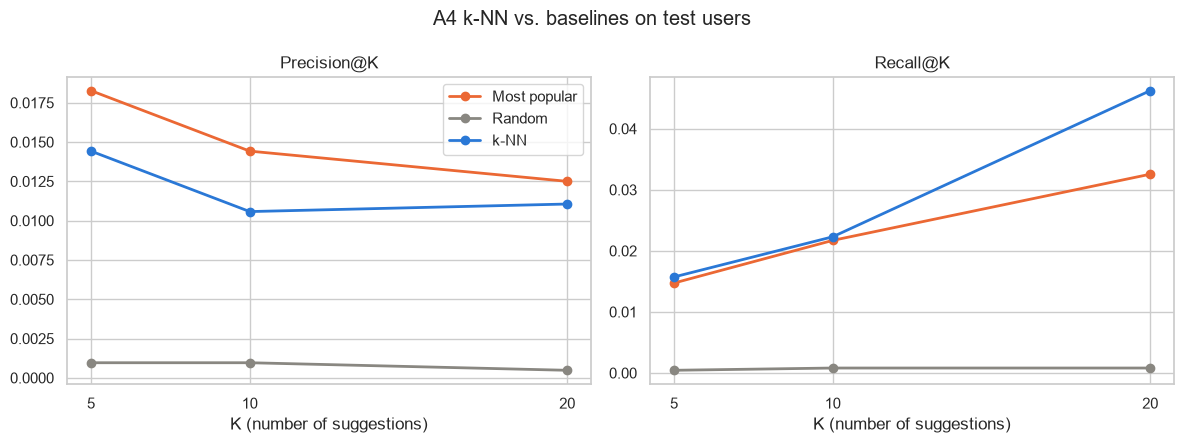

In [80]:
# Final evaluation on the test users
F_a4 = a4_features(venues_train, A4_W_LOC, A4_W_POP)
nn_a4 = NearestNeighbors(metric="euclidean").fit(F_a4)
a4_results = evaluate_users(sorted(test_users), F_a4, nn_a4)
print(a4_results.round(4).to_string(index=False))
a4_results.to_csv(RES + "a4_results.csv", index=False)
for _, r in a4_results.iterrows():
    for metric in ["Precision@K", "Recall@K", "HitRate@K"]:
        record("A4 k-NN", f"{metric.replace('K', str(r['K']))}", r[metric], r["method"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
colors = {"k-NN": SERIES[0], "Most popular": SERIES[1], "Random": GREY}
for ax, metric in zip(axes, ["Precision@K", "Recall@K"]):
    for m, sub in a4_results.groupby("method"):
        ax.plot(sub["K"], sub[metric], marker="o", lw=2, color=colors[m], label=m)
    ax.set_xticks(KS)
    ax.set_xlabel("K (number of suggestions)")
    ax.set_title(metric)
axes[0].legend()
plt.suptitle("A4 k-NN vs. baselines on test users")
save_fig("a4_precision_recall.png")

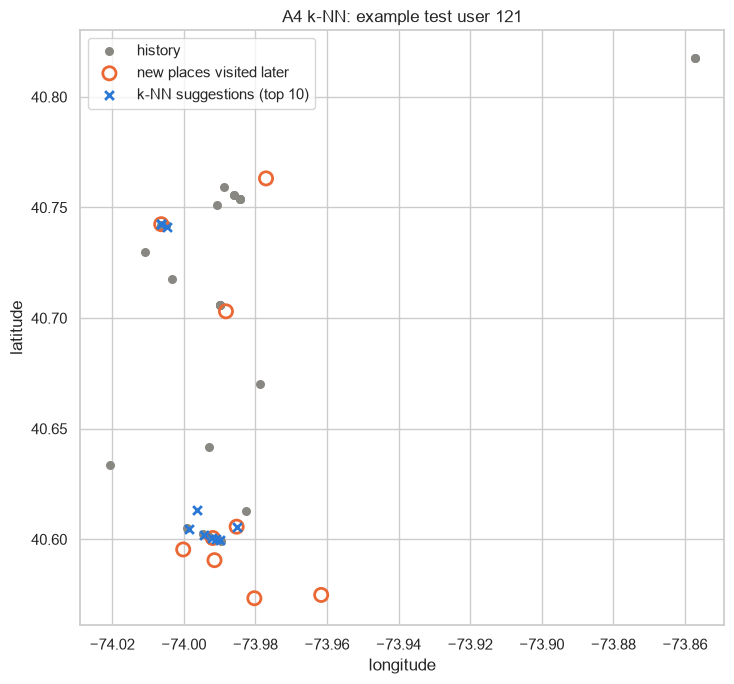

Correct suggestions for this user: 2 of 10


In [81]:
# Example: one test user's history, k-NN suggestions and the new places they really visited
example = None
for uid in sorted(test_users):
    hist_known, seen, target = split_user(uid)
    if len(hist_known) >= 5 and len(target) >= 3:
        suggestions = recommend(hist_known, seen, F_a4, nn_a4)[:10]
        if set(suggestions) & target:
            example = (uid, hist_known, suggestions, target)
            break

if example:
    uid, hist_known, suggestions, target = example
    vt = venues_train
    plt.figure(figsize=(7.5, 7))
    plt.scatter(vt.loc[hist_known, "longitude"], vt.loc[hist_known, "latitude"], s=30, color=GREY, label="history")
    plt.scatter(vt.loc[list(target), "longitude"], vt.loc[list(target), "latitude"], s=90, facecolors="none",
                edgecolors=SERIES[1], lw=2, label="new places visited later")
    plt.scatter(vt.loc[suggestions, "longitude"], vt.loc[suggestions, "latitude"], s=40, marker="x",
                color=SERIES[0], lw=2, label="k-NN suggestions (top 10)")
    plt.xlabel("longitude")
    plt.ylabel("latitude")
    plt.title(f"A4 k-NN: example test user {uid}")
    plt.legend()
    save_fig("a4_example_user.png")
    print("Correct suggestions for this user:", len(set(suggestions) & target), "of 10")
else:
    print("No example user with a correct suggestion was found.")

In [82]:
# A6 Markov Chain (outside class): what kind of place comes next?
# Reference: J. R. Norris, Markov Chains. Cambridge University Press, 1997.
# Model input: each check-in paired with the same user's next check-in on the same day.
T_IDX = {t: i for i, t in enumerate(THEME_LIST)}
P_IDX = {p: i for i, p in enumerate(PERIODS)}
ordered = fs.sort_values(["user_id", "local_time"])
next_theme = ordered.groupby("user_id")["theme"].shift(-1)
next_time = ordered.groupby("user_id")["local_time"].shift(-1)
same_day = next_time.notna() & (next_time.dt.date == ordered["local_time"].dt.date)
pairs = pd.DataFrame({"user_id": ordered["user_id"][same_day],
                      "cur": ordered["theme"][same_day].map(T_IDX),
                      "nxt": next_theme[same_day].map(T_IDX),
                      "per": ordered["light_period"][same_day].map(P_IDX)}).dropna().astype({"cur": int, "nxt": int, "per": int})
pair_is_test = pairs["user_id"].isin(test_users)
train_pairs, test_pairs = pairs[~pair_is_test], pairs[pair_is_test]
print("Same-day visit pairs:", len(pairs), "| train:", len(train_pairs), "| test:", len(test_pairs))
record("A6 Markov Chain", "same_day_pairs", len(pairs))


def fit_markov(df, alpha, use_period):
    if use_period:
        counts = np.full((len(PERIODS), len(THEME_LIST), len(THEME_LIST)), alpha, dtype=float)
        np.add.at(counts, (df["per"].values, df["cur"].values, df["nxt"].values), 1)
    else:
        counts = np.full((len(THEME_LIST), len(THEME_LIST)), alpha, dtype=float)
        np.add.at(counts, (df["cur"].values, df["nxt"].values), 1)
    return counts / counts.sum(axis=-1, keepdims=True)


def markov_proba(P, df, use_period):
    return P[df["per"].values, df["cur"].values] if use_period else P[df["cur"].values]


def sequence_scores(proba, y):
    top3 = np.argsort(-proba, axis=1)[:, :3]
    return {"top1_accuracy": np.mean(proba.argmax(axis=1) == y),
            "top3_accuracy": np.mean([y[i] in top3[i] for i in range(len(y))]),
            "log_loss": log_loss(y, proba, labels=list(range(len(THEME_LIST))))}


# Tuning on 20% of the train users
rng = np.random.default_rng(SEED)
tp_users = sorted(train_pairs["user_id"].unique())
val_u = set(rng.choice(tp_users, size=int(round(0.2 * len(tp_users))), replace=False))
fit_part = train_pairs[~train_pairs["user_id"].isin(val_u)]
val_part = train_pairs[train_pairs["user_id"].isin(val_u)]
rows = []
for alpha in [0.1, 1, 5]:
    for use_period in [False, True]:
        P = fit_markov(fit_part, alpha, use_period)
        s = sequence_scores(markov_proba(P, val_part, use_period), val_part["nxt"].values)
        rows.append({"alpha": alpha, "uses light period": use_period, **s})
a6_tuning = pd.DataFrame(rows).sort_values("log_loss")
print(a6_tuning.round(4).to_string(index=False))
A6_ALPHA = float(a6_tuning.iloc[0]["alpha"])
A6_PERIOD = bool(a6_tuning.iloc[0]["uses light period"])
print(f"\nChosen: alpha = {A6_ALPHA}, uses light period = {A6_PERIOD}")

Same-day visit pairs: 34317 | train: 27327 | test: 6990
 alpha  uses light period  top1_accuracy  top3_accuracy  log_loss
   1.0               True         0.5159         0.8216    1.3748
   0.1               True         0.5159         0.8216    1.3750
   5.0               True         0.5159         0.8216    1.3771
   0.1              False         0.5063         0.8193    1.3805
   1.0              False         0.5063         0.8193    1.3806
   5.0              False         0.5063         0.8193    1.3810

Chosen: alpha = 1.0, uses light period = True


In [56]:
# Final model on all train users, tested on the test users
P_a6 = fit_markov(train_pairs, A6_ALPHA, A6_PERIOD)
y_next = test_pairs["nxt"].values
rows = [{"model": "Markov Chain", **sequence_scores(markov_proba(P_a6, test_pairs, A6_PERIOD), y_next)}]

# Baselines
freq = np.bincount(train_pairs["nxt"].values, minlength=len(THEME_LIST)) / len(train_pairs)
freq_proba = np.tile(freq, (len(test_pairs), 1))
rows.append({"model": "Baseline: theme frequencies (always most common)", **sequence_scores(freq_proba, y_next)})
repeat = np.full((len(test_pairs), len(THEME_LIST)), 1e-6)
repeat[np.arange(len(test_pairs)), test_pairs["cur"].values] = 1.0
order_freq = np.argsort(-freq)
for i, c in enumerate(test_pairs["cur"].values):     # 2nd and 3rd guesses: most common other themes
    others = [t for t in order_freq if t != c][:2]
    repeat[i, others[0]], repeat[i, others[1]] = 0.5, 0.25
repeat = repeat / repeat.sum(axis=1, keepdims=True)
rep = sequence_scores(repeat, y_next)
rep["log_loss"] = np.nan    # not a real probability model
rows.append({"model": "Baseline: repeat current theme", **rep})

a6_results = pd.DataFrame(rows)
print(a6_results.round(4).to_string(index=False))
a6_results.to_csv(RES + "a6_results.csv", index=False)
for _, r in a6_results.iterrows():
    for metric in ["top1_accuracy", "top3_accuracy", "log_loss"]:
        if not pd.isna(r[metric]):
            record("A6 Markov Chain", metric, r[metric], r["model"])

                                           model  top1_accuracy  top3_accuracy  log_loss
                                    Markov Chain         0.4971         0.8165    1.4078
Baseline: theme frequencies (always most common)         0.4931         0.7524    1.5069
                  Baseline: repeat current theme         0.4496         0.7901       NaN


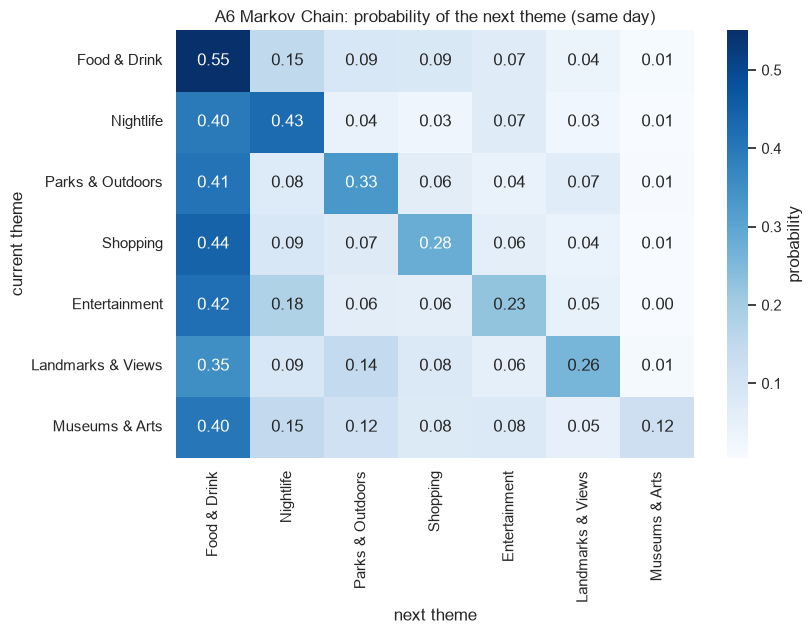

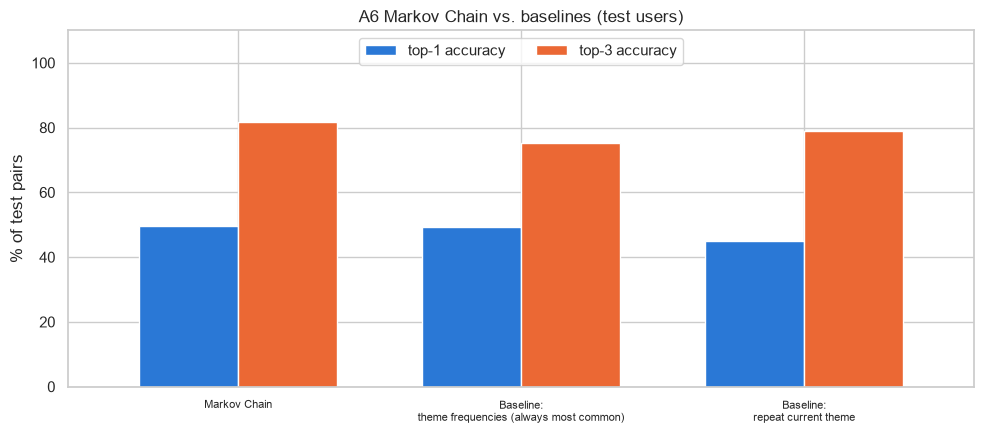

Most likely next stops after each theme (excluding the same theme):
  after Food & Drink       -> Nightlife (0.15), Parks & Outdoors (0.09)
  after Nightlife          -> Food & Drink (0.40), Entertainment (0.07)
  after Parks & Outdoors   -> Food & Drink (0.41), Nightlife (0.08)
  after Shopping           -> Food & Drink (0.44), Nightlife (0.09)
  after Entertainment      -> Food & Drink (0.42), Nightlife (0.18)
  after Landmarks & Views  -> Food & Drink (0.35), Parks & Outdoors (0.14)
  after Museums & Arts     -> Food & Drink (0.40), Nightlife (0.15)


In [83]:
# Chart 1: transition table P(next theme | current theme), from all train pairs
P_simple = fit_markov(train_pairs, A6_ALPHA, use_period=False)
trans = pd.DataFrame(P_simple, index=THEME_LIST, columns=THEME_LIST)
trans.round(4).to_csv(RES + "a6_transition_matrix.csv")
plt.figure(figsize=(8.5, 6.5))
sns.heatmap(trans, annot=True, fmt=".2f", cmap="Blues", cbar_kws={"label": "probability"})
plt.xlabel("next theme")
plt.ylabel("current theme")
plt.title("A6 Markov Chain: probability of the next theme (same day)")
save_fig("a6_transitions.png")

# Chart 2: Markov Chain vs. baselines
plot_df = a6_results.set_index("model")[["top1_accuracy", "top3_accuracy"]] * 100
ax = plot_df.plot(kind="bar", figsize=(10, 4.5), color=[SERIES[0], SERIES[1]], width=0.7, edgecolor="white")
ax.set_ylabel("% of test pairs")
ax.set_xlabel("")
ax.set_xticklabels([t.get_text().replace(": ", ":\n") for t in ax.get_xticklabels()], rotation=0, fontsize=8)
ax.set_title("A6 Markov Chain vs. baselines (test users)")
ax.set_ylim(0, 110)
ax.legend(["top-1 accuracy", "top-3 accuracy"], loc="upper center", ncol=2)
save_fig("a6_vs_baselines.png")

print("Most likely next stops after each theme (excluding the same theme):")
for t in THEME_LIST:
    nxt = trans.loc[t].drop(t).sort_values(ascending=False).head(2)
    print(f"  after {t:18s} -> " + ", ".join(f"{n} ({p:.2f})" for n, p in nxt.items()))

In [84]:
summary_p2 = pd.DataFrame(SUMMARY)
summary_p2.to_csv(RES + "phase2_summary.csv", index=False)
print(summary_p2.to_string(index=False))

             algorithm                                metric      value                                             note
                  Data                   foursquare_checkins 89118.0000                                                 
                  Data                      foursquare_users  1078.0000                                                 
                  Data                     foursquare_venues  8645.0000                                                 
                  Data                         google_places 36888.0000                                                 
                  Data                          bridge_hours 16057.0000                                                 
A1 Logistic Regression                              accuracy     0.1838                              Logistic Regression
A1 Logistic Regression                         top3_accuracy     0.5909                              Logistic Regression
A1 Logistic Regression          

In [85]:
# Proof that Phase 2 did not change the files Phase 1 saved
FINGERPRINT_AFTER = {f: fingerprint(OUT + f) for f in P1_FILES}
for f in P1_FILES:
    print(f"{f:38s} unchanged: {FINGERPRINT_BEFORE[f] == FINGERPRINT_AFTER[f]}")
assert FINGERPRINT_BEFORE == FINGERPRINT_AFTER, "A Phase 1 file was modified!"

print("\nCharts saved in", FIG_P2)
for f in sorted(os.listdir(FIG_P2)):
    print("  ", f)
print("Result tables saved in", RES)
for f in sorted(os.listdir(RES)):
    print("  ", f)

foursquare_checkins_clean.csv          unchanged: True
google_places_clean.csv                unchanged: True
brooklyn_bridge_clean.csv              unchanged: True

Charts saved in ../figures/phase2/
   a1_confusion.png
   a1_roc.png
   a1_suitability.png
   a2_effects.png
   a2_pred_vs_actual.png
   a2_week.png
   a3_elbow_silhouette.png
   a3_map.png
   a3_profiles.png
   a3_theme_mix.png
   a4_example_user.png
   a4_precision_recall.png
   a5_best_time.png
   a5_importance.png
   a5_pred_vs_actual.png
   a6_transitions.png
   a6_vs_baselines.png
Result tables saved in ../results/
   a1_results.csv
   a1_suitability_by_period.csv
   a2_a5_comparison.csv
   a2_tuning.csv
   a3_tuning.csv
   a3_venue_groups.csv
   a4_results.csv
   a4_tuning.csv
   a6_results.csv
   a6_transition_matrix.csv
   phase2_summary.csv
